# HEART / Ugi-4CR — Priority 1: Interactive, Checkpointed Library Validation

**Goal:** Determine whether the existing Ugi-4CR virtual library is suitable for LUMI-style continual pretraining, using actual measured evidence. **No model training or dataset modification.** This interactive run writes into a separate output/cache folder and will not mix its results with the previous failed Slurm attempt.

**Two execution modes:** Interactive Run All performs only pilot; the NEW matching Slurm script explicitly enables automated full scanning.

**Why this version:** The previous Slurm batch job failed, but its error is not visible here. This notebook does not assume a cause. It runs a **small pilot before any full scan**, allowing us to diagnose missing paths, Python environment problems, LMDB schema differences, or workers failing.

**Default behavior is SAFE:** Running all cells performs an inventory, a full sidecar census, a two-shard metadata pilot, and a small LMDB pilot. It **does not scan the remaining thousands of shards** until you explicitly enable a batch. All source data are read-only. Logs, figures, and reports are written under the active notebook folder. The large SQLite identity index is stored separately.

**Evidence rule:** A pilot is not proof that all ~15.18M records pass. The final report must say `INCOMPLETE` until the complete audit finishes. The production loader remains a separate runtime-verification gate.


## Running this version: Interactive pilot OR unattended Slurm full audit

**The notebook does not submit Slurm jobs.** Jupyter **Run All** executes cells in your current kernel only. In the default interactive mode, it runs inventory, full sidecar census, one train + one validation pilot, LMDB pilot, and an **INCOMPLETE** report. It does **not** scan all 3,049 shards automatically.

**Unattended mode:** Use the matching NEW script `HEART_Ugi_Priority1_AutoFull_run.sbatch` from a terminal. It sets `HEART_AUDIT_AUTORUN=1` and runs *this* notebook non-interactively. After pilots, it processes every remaining shard in resumable chunks; it stops immediately on verified pilot problems. After all shards, it automatically performs the expanded LMDB probe (up to 3,500 samples), forensics, figures, and final evidence decision.

The `.sbatch` is an entirely new runner for **this** notebook, not the previously failed batch script. You must submit it manually using `sbatch`; running notebook cells never submits it.

**Original data and HEART checkpoints are read-only.** No model training. Do not run interactive and Slurm audits simultaneously against the same SQLite cache.


## Quick kernel check — run this FIRST (standard-library only)

In [1]:
import sys, os, importlib.util
from pathlib import Path
print('Notebook Python interpreter:',sys.executable)
for name in ['numpy','pandas','matplotlib','rdkit','lmdb','joblib','IPython']:
    print(f'{name:12s} available:',importlib.util.find_spec(name) is not None)
print('Current notebook folder:',Path.cwd().resolve())
print('Ugi root exists:',Path(os.getenv('HEART_UGI_ROOT','/project/yli4/ypan/lipid_library/lmdb')).is_dir())
print('Stage-06 view exists:',Path(os.getenv('HEART_UGI_VIEW','/project/yli4/ypan/audits/ugi_3d_final_view')).is_dir())
print('If any required dependency is missing, STOP before running Setup.')


Notebook Python interpreter: /home/ypan/.conda/envs/heart_gpu/bin/python
numpy        available: True
pandas       available: True
matplotlib   available: True
rdkit        available: True
lmdb         available: True
joblib       available: True
IPython      available: True
Current notebook folder: /mnt/home/ypan/heart_liver/model_train
Ugi root exists: True
Stage-06 view exists: True
If any required dependency is missing, STOP before running Setup.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from IPython.display import display, Markdown
import os, sys, json, csv, gzip, pickle, sqlite3, hashlib, random, time, traceback, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
RDLogger.DisableLog('rdApp.*')

# The Jupyter working directory is the same folder you opened in the file browser.
# On your cluster this can resolve to /mnt/home/ypan/... instead of /home/ypan/...
NOTEBOOK_DIR = Path.cwd().resolve()
UGI = Path(os.getenv('HEART_UGI_ROOT','/project/yli4/ypan/lipid_library/lmdb')).expanduser()
VIEW = Path(os.getenv('HEART_UGI_VIEW','/project/yli4/ypan/audits/ugi_3d_final_view')).expanduser()
REPO = Path(os.getenv('HEART_REPO',str(NOTEBOOK_DIR/'heart-molecular-pretraining'))).expanduser()
GENERAL_CKPT = Path(os.getenv('HEART_GENERAL_CKPT','/project/yli4/ypan/runs/h200/full/heart-h200-b448-v1/checkpoint_best.pt')).expanduser()
AUDIT = Path(os.getenv('HEART_AUDIT_OUT',str(NOTEBOOK_DIR/'ugi_priority1_interactive_evidence'))).expanduser()
AUDIT.mkdir(parents=True,exist_ok=True)
PLOTS = AUDIT/'figures'; PLOTS.mkdir(parents=True,exist_ok=True)
# Keep large SQLite identity index on project storage when accessible and writable.
_PREFERRED_CACHE = Path('/project/yli4/ypan/audits/ugi_priority1_interactive_evidence/cache')
_DEFAULT_CACHE = _PREFERRED_CACHE if Path('/project/yli4/ypan/audits').is_dir() and os.access('/project/yli4/ypan/audits',os.W_OK) else AUDIT/'cache'
CACHE_DIR = Path(os.getenv('HEART_AUDIT_CACHE',str(_DEFAULT_CACHE))).expanduser()
CACHE_DIR.mkdir(parents=True,exist_ok=True)

RUN_FULL_AUDIT = False              # old auto-run switch disabled; use explicit pilot/batch cells below
RUN_LMDB_PROBE = True               # real sampled payloads, only after the metadata audit
RUN_FORENSIC_EXAMPLES = True         # if duplicates or leakage, trace real molecular examples (second metadata pass)
RUN_PRODUCTION_DRY_RUN = False      # KEEP FALSE: launch command has NOT been verified safe/non-training
MAX_PROBE_RECORDS = 32             # small pilot initially; raise to 3500 for final full-library probe
SQL_BATCH = 3000
SEED = 20261117

# Start with only 4 CPU workers on the interactive workstation.
# Increase to 16 or 32 after the pilot succeeds; memory capacity alone does not
# eliminate shared-disk or SQLite throughput bottlenecks.
# joblib uses loky (spawn-like subprocesses) so it works in Jupyter/nbconvert.
try:
    ALLOCATED_CPUS = len(os.sched_getaffinity(0))
except AttributeError:
    ALLOCATED_CPUS = os.cpu_count() or 1
if os.getenv('SLURM_CPUS_PER_TASK'):
    ALLOCATED_CPUS = min(ALLOCATED_CPUS, int(os.environ['SLURM_CPUS_PER_TASK']))
REQUESTED_WORKERS = int(os.getenv('HEART_AUDIT_WORKERS', '4'))
AUDIT_WORKERS = max(1, min(REQUESTED_WORKERS, max(1, ALLOCATED_CPUS - 2)))
print(f'CPU allocation visible: {ALLOCATED_CPUS}; canonicalization workers: {AUDIT_WORKERS}')

CORE = Chem.MolFromSmiles('C(=O)NCC(=O)N')  # diagnostic motif, NOT proof of Ugi synthetic origin

def utc_now(): return datetime.now(timezone.utc).isoformat()
def read_json(path):
    try: return json.loads(Path(path).read_text(encoding='utf-8'))
    except (OSError, ValueError): return None

def sha256(path):
    p=Path(path)
    if not p.is_file(): return None
    h=hashlib.sha256()
    with p.open('rb') as f:
        for ch in iter(lambda:f.read(1024*1024),b''):h.update(ch)
    return h.hexdigest()

def write_json(name,obj):
    path=AUDIT/name
    path.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str)+'\n',encoding='utf-8')
    return path

def canonical_and_mol(s):
    if not isinstance(s,str) or not s.strip():return None,None
    try:
        m=Chem.MolFromSmiles(s.strip())
        if m is None: return None,None
        return Chem.MolToSmiles(m,canonical=True,isomericSmiles=True),m
    except Exception:return None,None

def fp(can): return hashlib.blake2b(can.encode('utf-8'),digest_size=16).digest()

def figsave(name):
    path=PLOTS/name
    plt.tight_layout();plt.savefig(path,dpi=175,bbox_inches='tight');plt.show();plt.close()
    print('Figure:',path)

print('UGI source exists:',UGI.is_dir(),UGI)
print('Stage-06 view exists:',VIEW.is_dir(),VIEW)
print('REPO exists:',REPO.is_dir(),REPO)
print('REPORTS visible in Jupyter (source untouched):',AUDIT)
print('LARGE SQLite cache (project-backed):',CACHE_DIR)
print('Notebook home:',Path.home())
print('Interactive pilot by default; full scan requires explicit batch action.')
print('Notebook working folder:',NOTEBOOK_DIR)

CPU allocation visible: 32; canonicalization workers: 24
UGI source exists: True /project/yli4/ypan/lipid_library/lmdb
Stage-06 view exists: True /project/yli4/ypan/audits/ugi_3d_final_view
REPO exists: True /mnt/home/ypan/heart_liver/model_train/heart-molecular-pretraining
REPORTS visible in Jupyter (source untouched): /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence
LARGE SQLite cache (project-backed): /project/yli4/ypan/audits/ugi_priority1_interactive_evidence/cache
Notebook home: /home/ypan
Interactive pilot by default; full scan requires explicit batch action.
Notebook working folder: /mnt/home/ypan/heart_liver/model_train


## Preflight — verify paths and packages before a long scan

This quick check records actual Python, CPU affinity, packages, and file paths. A missing package or inaccessible source directory is **not** a molecular quality failure; fix the environment first. The full scan is not started here.


In [3]:
import importlib.util, shutil
required = ['numpy','pandas','matplotlib','rdkit','lmdb','joblib','IPython']
package_status = {p: importlib.util.find_spec(p) is not None for p in required}
paths = {'notebook_folder':NOTEBOOK_DIR,'Ugi_dataset':UGI,'Stage06_view':VIEW,
         'model_repo':REPO,'general_checkpoint':GENERAL_CKPT,'report_folder':AUDIT,'SQLite_cache':CACHE_DIR}
path_status = {k:{'path':str(p),'exists':p.exists(),'realpath':str(p.resolve()) if p.exists() else None}
               for k,p in paths.items()}
preflight_report = {'time_utc':utc_now(),'python':sys.executable,
                    'allocated_cpu_affinity':ALLOCATED_CPUS,'workers_for_pilot':AUDIT_WORKERS,
                    'packages':package_status,'paths':path_status,
                    'disk_free_report_GB':round(shutil.disk_usage(AUDIT).free/1e9,2),
                    'disk_free_cache_GB':round(shutil.disk_usage(CACHE_DIR).free/1e9,2)}
write_json('00_preflight.json',preflight_report)
display(pd.DataFrame([{'Dependency':k,'Available':v} for k,v in package_status.items()]))
display(pd.DataFrame([{'Source':k,**v} for k,v in path_status.items()]))
print('Python:',sys.executable,'| CPU affinity:',ALLOCATED_CPUS,'| pilot workers:',AUDIT_WORKERS)
print('Free storage (report/cache, GB):', preflight_report['disk_free_report_GB'],preflight_report['disk_free_cache_GB'])
print('Required for pilot: Ugi dataset, Stage06 view, NumPy/RDKit/joblib/lmdb.')
if not all(package_status.values()):print('ACTION: Some packages are missing. Do not launch the metadata pilot until resolved.')
if not (UGI.is_dir() and VIEW.is_dir()):print('ACTION: Fix UGI or VIEW path above before continuing.')


,Dependency,Available
0,numpy,True
1,pandas,True
2,matplotlib,True
3,rdkit,True
4,lmdb,True
5,joblib,True
6,IPython,True


,Source,path,exists,realpath
0,notebook_folder,/mnt/home/ypan/heart_liver/model_train,True,/mnt/home/ypan/heart_liver/model_train
1,Ugi_dataset,/project/yli4/ypan/lipid_library/lmdb,True,/mnt/project/yli4/ypan/lipid_library/lmdb
2,Stage06_view,/project/yli4/ypan/audits/ugi_3d_final_view,True,/mnt/project/yli4/ypan/audits/ugi_3d_final_view
3,model_repo,/mnt/home/ypan/heart_liver/model_train/heart-m...,True,/mnt/home/ypan/heart_liver/model_train/heart-m...
4,general_checkpoint,/project/yli4/ypan/runs/h200/full/heart-h200-b...,True,/mnt/project/yli4/ypan/runs/h200/full/heart-h2...
5,report_folder,/mnt/home/ypan/heart_liver/model_train/ugi_pri...,True,/mnt/home/ypan/heart_liver/model_train/ugi_pri...
6,SQLite_cache,/project/yli4/ypan/audits/ugi_priority1_intera...,True,/mnt/project/yli4/ypan/audits/ugi_priority1_in...


Python: /home/ypan/.conda/envs/heart_gpu/bin/python | CPU affinity: 32 | pilot workers: 24
Free storage (report/cache, GB): 35825.74 345554.22
Required for pilot: Ugi dataset, Stage06 view, NumPy/RDKit/joblib/lmdb.


## 1 | Immutable source inventory and split integrity

**Evidence produced:** display declared record and shard counts, the train/validation allocation, and separate historical Stage-05 and Stage-06 statuses. Disjoint split membership at this stage means **disjoint shard assignment**, not necessarily disjoint molecular identity. Exact train/validation molecular leakage is evaluated in Section 3.


In [4]:
manifest=read_json(UGI/'manifest.json')
splits=read_json(UGI/'splits.json')
qc=read_json(UGI/'quality_report.json')
view=read_json(VIEW/'final_dataset_view.json')
ready=read_json(UGI/'library_3d_ready.json')
SOURCE_FILES={'manifest':UGI/'manifest.json','splits':UGI/'splits.json','stage05_quality_report':UGI/'quality_report.json',
              'stage06_final_view':VIEW/'final_dataset_view.json','stage06_readiness_receipt':UGI/'library_3d_ready.json'}
SOURCE_HASHES={k:sha256(v) for k,v in SOURCE_FILES.items()}
INV={'generated_utc':utc_now(),'files':{k:{'path':str(v),'present':v.is_file(),'sha256':SOURCE_HASHES[k]} for k,v in SOURCE_FILES.items()},'issues':[]}
items=[]; SPLIT_BY_REL={}; MANIFEST_BY_REL={}; VIEW_BY_REL={}

if not manifest or not splits:
    INV['issues'].append('MISSING manifest.json and/or splits.json: run on HPC with mounted Ugi dataset')
else:
    entries=manifest.get('shards',[])
    MANIFEST_BY_REL={str(x['lmdb']):x for x in entries}
    t=set(map(str,splits.get('train',[])));v=set(map(str,splits.get('valid',[])))
    SPLIT_BY_REL={rel:split for split,refs in [('train',t),('valid',v)] for rel in refs}
    if len(MANIFEST_BY_REL)!=len(entries): INV['issues'].append('DUPLICATED shard names in manifest')
    if not t or not v:INV['issues'].append('Missing or empty train/valid set')
    if t & v:INV['issues'].append(f'Shard overlap between train and valid: {len(t&v)}')
    if t|v!=set(MANIFEST_BY_REL):INV['issues'].append('Split union does not equal manifest shard set')
    declared_total=sum(int(x['n_records']) for x in entries)
    if declared_total!=int(manifest.get('n_records',-1)):INV['issues'].append('Manifest n_records != per-shard sum')
    for split,refs in [('train',t),('valid',v)]:
        items.append({'split':split,'shards':len(refs),'declared_records':sum(int(MANIFEST_BY_REL[x]['n_records']) for x in refs if x in MANIFEST_BY_REL)})
    INV.update({'manifest_declared_records':manifest.get('n_records'),'manifest_shards':len(entries),'split_shards_disjoint':not bool(t&v),'split_complete':t|v==set(MANIFEST_BY_REL),'declared_per_split':items})
if view:
    VIEW_BY_REL={str(x['lmdb']):x for x in view.get('shards',[])}
    if manifest and set(VIEW_BY_REL)!=set(MANIFEST_BY_REL):INV['issues'].append('Stage-06 view shard set differs from manifest')
else:INV['issues'].append('Stage-06 final_dataset_view.json unavailable')
if not ready:INV['issues'].append('Stage-06 readiness receipt unavailable or unreadable')
INV['historical_stage05_passed']=qc.get('passed') if isinstance(qc,dict) else None
INV['view_index_validated_flag']=view.get('data_index_validated') if isinstance(view,dict) else None
INV['view_original_stage05_passed_flag']=view.get('source_original_quality_passed') if isinstance(view,dict) else None
INV['stage06_receipt_keys']=list(ready) if isinstance(ready,dict) else []
INV['stage06_view_keys']=list(view) if isinstance(view,dict) else []
if isinstance(ready,dict) and (ready.get('ready') is False or ready.get('passed') is False):
    INV['issues'].append('Stage-06 readiness explicitly reports failure')
if isinstance(view,dict) and view.get('data_index_validated') is False:
    INV['issues'].append('Stage-06 source data_index_validated explicitly false')
if isinstance(view,dict) and view.get('source_lmdb_dir'):
    declared_source=Path(view['source_lmdb_dir'])
    if declared_source.is_dir() and declared_source.resolve()!=UGI.resolve():
        INV['issues'].append(f'Stage-06 view references a DIFFERENT source root: {declared_source}')

write_json('01_source_inventory.json',INV)
print('Manifest records:', INV.get('manifest_declared_records'),'| shards:',INV.get('manifest_shards'))
print('Historical Stage-05 QC passed:',INV['historical_stage05_passed'])
print('Stage-06 final view index validated:',INV['view_index_validated_flag'])
print('Stage-06 receipt present:',bool(ready),'| keys:',INV['stage06_receipt_keys'])
if items:display(pd.DataFrame(items))
print('INVENTORY ISSUES:',INV['issues'] or 'none')
print('Evidence:',AUDIT/'01_source_inventory.json')

Manifest records: 15182715 | shards: 3049
Historical Stage-05 QC passed: False
Stage-06 final view index validated: True
Stage-06 receipt present: True | keys: ['config_fingerprint', 'coordinate_slots_per_record', 'full_verification', 'index_stats', 'loader_smoke_passed', 'manifest_sha256', 'n_records', 'n_records_split', 'n_shards', 'original_quality_passed', 'policy', 'quality_report_sha256', 'ready', 'shard_stats', 'smoke', 'splits_sha256', 'stored_2d_conformer', 'validation_sha256', 'view_file', 'view_sha256']


,split,shards,declared_records
0,train,3043,15152801
1,valid,6,29914


INVENTORY ISSUES: none
Evidence: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/01_source_inventory.json


## 2 | Full Stage-06 3D sidecar census — every record, not just a readiness receipt

Read the actual **3D index bytes** referenced by `final_dataset_view.json`, without regenerating conformers or modifying LMDB files. Produce the full-library histogram of valid 3D conformers per record (1–10), zero-success counts by shard, and comparisons with record counts in the manifest. Section 3 subsequently verifies each index entry against its corresponding `n_3d_success` metadata value.


INDEX CENSUS: 15182715 records; 3049 shards
Zero-success slots: 0 | out-of-range: 0
Index problems: 0


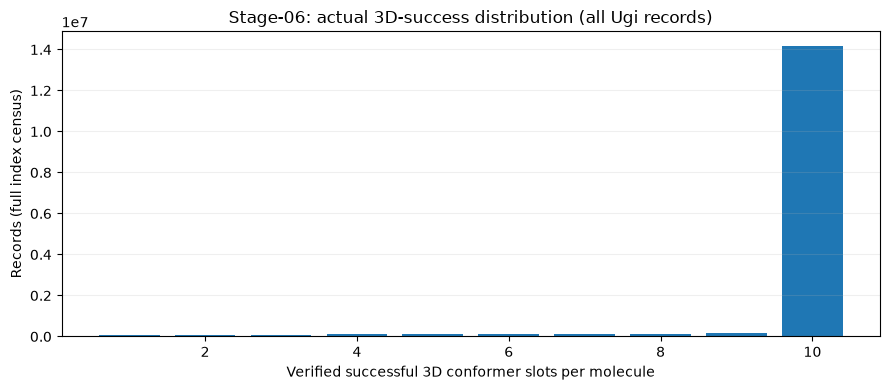

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/01_full_3d_success_histogram.png


In [5]:
sidecar_hist=Counter(); sidecar_rows=[]; sidecar_issues=[]; SIDE_COUNTS={}
if manifest and view:
    for rel,s in MANIFEST_BY_REL.items():
        if rel not in VIEW_BY_REL:
            sidecar_issues.append(f'MISSING view entry: {rel}'); continue
        idx_rel=VIEW_BY_REL[rel].get('index')
        if not idx_rel:
            sidecar_issues.append(f'MISSING index path: {rel}');continue
        idx_path=VIEW/idx_rel
        if not idx_path.is_file():
            sidecar_issues.append(f'MISSING index file: {idx_path}');continue
        counts=np.frombuffer(idx_path.read_bytes(),dtype=np.uint8)
        n_expected=int(s['n_records'])
        SIDE_COUNTS[rel]=counts
        if counts.size!=n_expected: sidecar_issues.append(f'{rel}: index has {counts.size}, expected {n_expected}')
        hist=np.bincount(counts,minlength=max(11,int(counts.max())+1 if counts.size else 11))
        for k,n in enumerate(hist):
            if n:sidecar_hist[k]+=int(n)
        if counts.size and (int(counts.min())<1 or int(counts.max())>10):
            sidecar_issues.append(f'{rel}: index out of 1-10 range ({int(counts.min())}-{int(counts.max())})')
        sidecar_rows.append({'shard':rel,'split':SPLIT_BY_REL.get(rel,'UNKNOWN'),'index_records':len(counts),
              'expected_records':n_expected,'n_3d_0':int(hist[0]),'n_3d_1':int(hist[1]),'n_3d_10':int(hist[10]),
              'mean_n3d':round(float(np.mean(counts)),3) if counts.size else None})
    del SIDE_COUNTS  # avoid accidentally holding all sidecar data in RAM; reread one shard in full audit
else:
    sidecar_issues.append('NOT_RUN: manifest and/or Stage-06 view missing')
SIDE_REPORT={'scope':'FULL_VIEW_SCAN' if manifest and view and len(sidecar_rows)==len(MANIFEST_BY_REL) else 'INCOMPLETE',
    'view_sha256':SOURCE_HASHES['stage06_final_view'],'declared_records':manifest.get('n_records') if manifest else None,
    'counted_records':sum(sidecar_hist.values()),'histogram_n3d':dict(sorted(sidecar_hist.items())),
    'shards_checked':len(sidecar_rows),'issues':sidecar_issues[:100], 'n_total_issues':len(sidecar_issues)}
if SIDE_REPORT['scope']=='FULL_VIEW_SCAN' and SIDE_REPORT['counted_records']!=SIDE_REPORT['declared_records']:
    sidecar_issues.append('Total indexed records != manifest declared records')
    SIDE_REPORT['n_total_issues']=len(sidecar_issues);SIDE_REPORT['issues']=sidecar_issues[:100]
write_json('02_3d_index_census.json',SIDE_REPORT)
if sidecar_rows:pd.DataFrame(sidecar_rows).to_csv(AUDIT/'02_3d_index_shards.csv',index=False)
print('INDEX CENSUS:',SIDE_REPORT['counted_records'],'records;',SIDE_REPORT['shards_checked'],'shards')
print('Zero-success slots:',sidecar_hist.get(0,0),'| out-of-range:',sum(v for k,v in sidecar_hist.items() if k>10))
print('Index problems:',SIDE_REPORT['n_total_issues'])
if sidecar_hist:
    plt.figure(figsize=(9,4));plt.bar(range(1,11),[sidecar_hist.get(i,0) for i in range(1,11)])
    plt.xlabel('Verified successful 3D conformer slots per molecule');plt.ylabel('Records (full index census)')
    plt.title('Stage-06: actual 3D-success distribution (all Ugi records)');plt.grid(axis='y',alpha=.2)
    figsave('01_full_3d_success_histogram.png')

## Metadata audit — definitions and resumable SQLite engine

This cell **defines functions only**; it does not begin scanning records. RDKit canonicalizes each SMILES and saves one digest per unique structure. `done` shards are recorded after their SQLite transaction commits, so the next batch can continue without restarting completed shards.

Large SQLite writes are done by **one writer**; subprocess workers only read source shards. This avoids concurrent SQLite locks. The metadata scan checks exact train/validation identity overlap only after **all shards** are processed. Hash collisions are extremely unlikely but exact SMILES adjudication remains appropriate for any critical forensic finding.


In [6]:
DB_PATH=CACHE_DIR/'ugi_priority1_identity.sqlite3'

def db_connect():
    con=sqlite3.connect(str(DB_PATH),timeout=180)
    con.execute('PRAGMA journal_mode=WAL')
    con.execute('PRAGMA synchronous=NORMAL')
    con.execute('PRAGMA cache_size=-131072')
    con.execute('CREATE TABLE IF NOT EXISTS meta(k TEXT PRIMARY KEY,v TEXT NOT NULL)')
    con.execute('''CREATE TABLE IF NOT EXISTS molecules(
        hash BLOB PRIMARY KEY,n_train INTEGER NOT NULL,n_valid INTEGER NOT NULL,n_total INTEGER NOT NULL)''')
    con.execute('''CREATE TABLE IF NOT EXISTS done(
        shard TEXT PRIMARY KEY,n_records INTEGER NOT NULL,stats_json TEXT NOT NULL,samples_json TEXT NOT NULL)''')
    con.commit();return con

def gate_fingerprints(con):
    for k,v in [('manifest_sha256',SOURCE_HASHES['manifest']),('splits_sha256',SOURCE_HASHES['splits']),
                ('view_sha256',SOURCE_HASHES['stage06_final_view'])]:
        old=con.execute('SELECT v FROM meta WHERE k=?',(k,)).fetchone()
        if old and old[0]!=str(v):raise RuntimeError(f'Cache SOURCE CHANGED for {k}: use a NEW AUDIT directory; do not reuse this DB')
        con.execute('INSERT OR IGNORE INTO meta(k,v) VALUES (?,?)',(k,str(v)))
    con.commit()

def _audit_one_shard(rel, expected, meta_path, index_path, split, seed):
    """CPU worker, read-only on input. Return complete per-shard evidence and canonical hashes.

    No SQLite access here: a *single writer* in the notebook owns SQLite transactions.
    Workers are independent and can be restarted safely after an interrupted run.
    """
    import csv, gzip, hashlib, random
    from collections import Counter
    from pathlib import Path
    import numpy as np
    from rdkit import Chem, RDLogger
    RDLogger.DisableLog('rdApp.*')
    meta = Path(meta_path)
    idx = Path(index_path)
    meta_stat, index_stat = meta.stat(), idx.stat()
    counts = np.frombuffer(idx.read_bytes(), dtype=np.uint8)
    if len(counts) != expected:
        raise RuntimeError(f'Stage-06 index length mismatch for {rel}: {len(counts)} vs {expected}')
    core = Chem.MolFromSmiles('C(=O)NCC(=O)N')
    rng = random.Random(seed + int.from_bytes(hashlib.blake2b(rel.encode(),digest_size=4).digest(),'big'))
    chosen = {0, expected - 1} if expected else set()
    if expected > 2: chosen.add(rng.randrange(expected))
    stats = {'shard':rel,'split':split,'expected':expected,'read':0,'noncontiguous_keys':0,
             'bad_3d_count':0,'sidecar_disagreement':0,'invalid_smiles':0,'fragmented_smiles':0,
             'without_ugi_like_motif':0,'heavy_over_256':0,'n3d_hist':{},'heavy_hist':{},
             'max_heavy_atoms':0,'examples':{},
             'metadata_size':meta_stat.st_size,'metadata_mtime_ns':meta_stat.st_mtime_ns,
             'index_size':index_stat.st_size,'index_mtime_ns':index_stat.st_mtime_ns}
    hist3d=Counter();heavyhist=Counter();samples=[];low3d_collected=0;hashes=[]
    with gzip.open(meta,'rt',encoding='utf-8',newline='') as f:
        reader=csv.DictReader(f)
        if not {'key','smi','n_3d_success'}.issubset(set(reader.fieldnames or [])):
            raise ValueError(f'Missing metadata fields in {meta}')
        for i,row in enumerate(reader):
            stats['read'] += 1
            try: key=int(row['key'])
            except Exception: key=-1
            if key!=i:
                stats['noncontiguous_keys']+=1
                stats['examples'].setdefault('noncontiguous_key',{'row':i,'key':row.get('key')})
            try: n3d=int(row['n_3d_success'])
            except Exception: n3d=-1
            hist3d[n3d]+=1
            if not 1<=n3d<=10:
                stats['bad_3d_count']+=1
                stats['examples'].setdefault('bad_3d_count',{'row':i,'n3d':n3d})
            if i>=len(counts) or n3d!=int(counts[i]):
                stats['sidecar_disagreement']+=1
                stats['examples'].setdefault('sidecar_disagreement',{'row':i,'metadata_n3d':n3d,
                    'view_index_n3d':int(counts[i]) if i<len(counts) else None})
            smi=row.get('smi')
            try:
                mol = Chem.MolFromSmiles(smi.strip()) if isinstance(smi,str) and smi.strip() else None
                can = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True) if mol is not None else None
            except Exception:
                can, mol = None, None
            if can is None:
                stats['invalid_smiles']+=1
                stats['examples'].setdefault('invalid_smiles',{'row':i,'smi':str(smi)[:150]})
            else:
                if '.' in can:
                    stats['fragmented_smiles']+=1
                    stats['examples'].setdefault('fragmented_smiles',{'row':i,'smi':can[:150]})
                if not mol.HasSubstructMatch(core):
                    stats['without_ugi_like_motif']+=1
                    stats['examples'].setdefault('without_ugi_like_motif',{'row':i,'smi':can[:150]})
                heavy=mol.GetNumHeavyAtoms()
                heavyhist[min(heavy,513)]+=1
                stats['max_heavy_atoms']=max(stats['max_heavy_atoms'],heavy)
                if heavy>256:
                    stats['heavy_over_256']+=1
                    stats['examples'].setdefault('heavy_over_256',{'row':i,'heavy':heavy,'smi':can[:100]})
                hashes.append(hashlib.blake2b(can.encode('utf-8'),digest_size=16).digest())
            if i in chosen or (1<=n3d<=2 and low3d_collected<2):
                samples.append({'shard':rel,'split':split,'key':i,'n3d':n3d,'smi':smi or '',
                                'selection':'random_or_edge' if i in chosen else 'low_n3d'})
                if n3d<=2 and i not in chosen:low3d_collected+=1
    stats['n3d_hist']={str(k):int(v) for k,v in hist3d.items()}
    stats['heavy_hist']={str(k):int(v) for k,v in heavyhist.items()}
    return rel, expected, stats, samples, hashes


def _check_cached_shard_source(con, rel, expected, meta, indexfile):
    """Fail rather than reuse a cache if a previously completed source changed."""
    cached=json.loads(con.execute('SELECT stats_json FROM done WHERE shard=?',(rel,)).fetchone()[0])
    m,i=meta.stat(),indexfile.stat()
    for field,actual in [('metadata_size',m.st_size),('metadata_mtime_ns',m.st_mtime_ns),
                         ('index_size',i.st_size),('index_mtime_ns',i.st_mtime_ns)]:
        if cached.get(field)!=actual:
            raise RuntimeError(f'Previously audited shard changed: {rel} / {field}. Use a NEW AUDIT cache.')
    if int(cached['expected'])!=expected:
        raise RuntimeError(f'Previously audited shard record count changed: {rel}')


def full_audit(target_rels=None, max_shards=None):
    """Parallel, read-only RDKit shard workers; serialized atomic SQLite writes."""
    if INV['issues']:raise RuntimeError('Cannot full audit until source inventory issues resolved: '+str(INV['issues'][:5]))
    if sidecar_issues:raise RuntimeError('Cannot full audit until sidecar issues resolved: '+str(sidecar_issues[:5]))
    from joblib import Parallel, delayed
    import inspect
    if 'return_as' not in inspect.signature(Parallel).parameters:
        raise RuntimeError('Please update joblib to >=1.3 (requires streaming return_as=generator)')
    con=db_connect()
    gate_fingerprints(con)
    done={rel:n for rel,n in con.execute('SELECT shard,n_records FROM done')}
    pending=[]
    for rel,entry in MANIFEST_BY_REL.items():
        expected=int(entry['n_records'])
        meta=UGI/Path(rel).parent/'records.csv.gz'
        indexfile=VIEW/VIEW_BY_REL[rel]['index']
        if not meta.is_file():raise FileNotFoundError(meta)
        if not indexfile.is_file():raise FileNotFoundError(indexfile)
        if rel in done:
            if int(done[rel])!=expected:raise RuntimeError('Cached n_records changed: '+rel)
            _check_cached_shard_source(con,rel,expected,meta,indexfile)
            continue
        pending.append((rel,expected,str(meta),str(indexfile),SPLIT_BY_REL[rel],SEED))
    print(f'Resumable SQLite: {len(done)} complete; {len(pending)} pending; workers={AUDIT_WORKERS}',flush=True)
    if target_rels is not None:
        selected=set(target_rels)
        pending=[x for x in pending if x[0] in selected]
    if max_shards is not None:
        pending=pending[:max(0,int(max_shards))]
    print('Selected pending shards for THIS call:', len(pending), flush=True)
    if not pending:
        con.close();return
    start=time.monotonic()
    progress_interval=5
    try:
        results=Parallel(n_jobs=AUDIT_WORKERS,backend='loky',return_as='generator',
                         pre_dispatch='2*n_jobs',batch_size=1,verbose=0)(
            delayed(_audit_one_shard)(*args) for args in pending)
        for count,(rel,expected,stats,samples,hashes) in enumerate(results,start=1):
            train_bit=int(stats['split']=='train');valid_bit=int(stats['split']=='valid')
            with con:
                for pos in range(0,len(hashes),SQL_BATCH):
                    # All identity writes are done on the parent process only.
                    payload=((h,train_bit,valid_bit) for h in hashes[pos:pos+SQL_BATCH])
                    con.executemany("""INSERT INTO molecules(hash,n_train,n_valid,n_total) VALUES(?,?,?,1)
                        ON CONFLICT(hash) DO UPDATE SET n_train=n_train+excluded.n_train,
                        n_valid=n_valid+excluded.n_valid,n_total=n_total+1""",payload)
                con.execute('INSERT INTO done(shard,n_records,stats_json,samples_json) VALUES(?,?,?,?)',
                            (rel,stats['read'],json.dumps(stats),json.dumps(samples)))
            if count%progress_interval==0 or count==len(pending):
                report={'completed_shards':len(done)+count,'total_shards':len(MANIFEST_BY_REL),
                        'completed_this_run':count,'pending_this_run':len(pending),'workers':AUDIT_WORKERS,
                        'elapsed_seconds':round(time.monotonic()-start,1),'last_shard':rel,
                        'updated_utc':utc_now()}
                write_json('03_live_progress.json',report)
                print('PARALLEL AUDIT:',report,flush=True)
    finally:
        con.close()

def summarize_full_audit():
    if not DB_PATH.is_file():return None
    con=db_connect()
    expected=len(MANIFEST_BY_REL)
    done_rows=con.execute('SELECT shard,n_records,stats_json FROM done').fetchall()
    allstats=[json.loads(j) for _,_,j in done_rows]
    count_rows=sum(st['read'] for st in allstats)
    total=Counter();n3d=Counter();heavy=Counter();bad_examples=[]
    for s in allstats:
        for fld in ['noncontiguous_keys','bad_3d_count','sidecar_disagreement','invalid_smiles',
                    'fragmented_smiles','without_ugi_like_motif','heavy_over_256']:
            total[fld]+=int(s.get(fld,0))
        for k,v in s.get('n3d_hist',{}).items():n3d[k]+=v
        for k,v in s.get('heavy_hist',{}).items():heavy[k]+=v
        for t,example in s.get('examples',{}).items():
            if len(bad_examples)<150:bad_examples.append({'shard':s['shard'],'issue':t,**example})
    sql_count=con.execute('''SELECT COUNT(*),COALESCE(SUM(n_total-1),0),
          COALESCE(SUM(CASE WHEN n_train>0 AND n_valid>0 THEN 1 ELSE 0 END),0),
          COALESCE(SUM(CASE WHEN n_train>1 AND n_valid=0 THEN 1 ELSE 0 END),0),
          COALESCE(SUM(CASE WHEN n_valid>1 AND n_train=0 THEN 1 ELSE 0 END),0)
          FROM molecules''').fetchone()
    uniq,extra,cross,tr_dup,va_dup=map(int,sql_count)
    full=bool(manifest and len(done_rows)==expected and count_rows==int(manifest['n_records']) and
              all(st['read']==st['expected'] for st in allstats))
    report={'generated_utc':utc_now(),'scope':'FULL' if full else 'INCOMPLETE',
       'expected_shards':expected,'audited_shards':len(done_rows),
       'expected_records':int(manifest['n_records']) if manifest else None,'audited_records':count_rows,
       'unique_canonical_molecules_hash_based':uniq,'duplicate_excess_records':extra,
       'canonical_train_valid_intersection':cross,'train_only_duplicate_molecules':tr_dup,
       'valid_only_duplicate_molecules':va_dup,'issues_full_counts':dict(total),
       'n3d_histogram':dict(n3d),'heavy_atom_histogram_cap513':dict(heavy),
       'source_hashes':SOURCE_HASHES,'identity_accounting_matches':bool(uniq+extra==count_rows-total.get('invalid_smiles',0)),
       'note':'BLAKE2b-128 canonical isomeric RDKit identity. FULL means all metadata visited, not automatic PASS.'}
    write_json('03_full_molecular_audit.json',report)
    pd.DataFrame(allstats).drop(columns=['n3d_hist','heavy_hist','examples'],errors='ignore').to_csv(AUDIT/'03_per_shard_stats.csv',index=False)
    pd.DataFrame(bad_examples).to_csv(AUDIT/'03_anomaly_examples.csv',index=False)
    con.close();return report



## Pilot 1 — audit **one train shard and one validation shard**, then inspect actual statistics

This is intentionally small and should be the first molecular audit. It writes to the *same resumable SQLite cache* as the later batches. It never falsely reports a full-dataset PASS. Rerunning this cell skips pilot shards already completed, rather than auditing additional shards.

Review `03_pilot_metadata_summary.json`, the diagnostic plot, and any reported metadata mismatches before continuing.


Pilot shards: ['shard-00000/train.lmdb', 'shard-00349/train.lmdb']
Resumable SQLite: 0 complete; 3049 pending; workers=24
Selected pending shards for THIS call: 2
PARALLEL AUDIT: {'completed_shards': 2, 'total_shards': 3049, 'completed_this_run': 2, 'pending_this_run': 2, 'workers': 24, 'elapsed_seconds': 2.2, 'last_shard': 'shard-00349/train.lmdb', 'updated_utc': '2026-11-17T23:16:54.453536+00:00'}


,shard,split,expected,read,noncontiguous_keys,bad_3d_count,sidecar_disagreement,invalid_smiles,fragmented_smiles,without_ugi_like_motif
0,shard-00000/train.lmdb,train,5000,5000,0,0,0,0,0,0
1,shard-00349/train.lmdb,valid,4990,4990,0,0,0,0,0,0


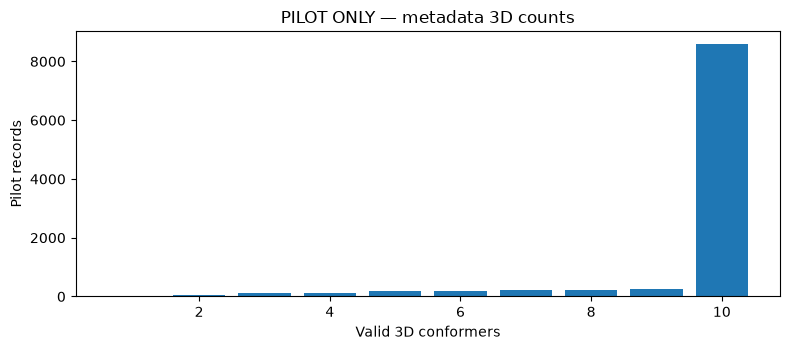

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/PILOT_metadata_3d_success.png
Pilot evidence: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/03_pilot_metadata_summary.json
The pilot is not a full-library PASS; inspect the per-shard anomalies before proceeding.


In [7]:
if not (manifest and splits and view):
    print('PILOT BLOCKED: Required source inventory unavailable. Correct paths in Setup.')
    UGI_REPORT = None
elif INV['issues'] or sidecar_issues:
    print('PILOT BLOCKED by inventory/sidecar issues:', (INV['issues']+sidecar_issues)[:8])
    UGI_REPORT = None
else:
    # Select a deterministic representative shard from each split, rather than
    # two neighboring shards that might both be training data.
    pilot_rels = [next((rel for rel in MANIFEST_BY_REL if SPLIT_BY_REL.get(rel)==split),None)
                  for split in ('train','valid')]
    pilot_rels = [rel for rel in pilot_rels if rel]
    print('Pilot shards:',pilot_rels)
    if len(pilot_rels)<2:
        print('PILOT BLOCKED: train and validation pilot shards were not found')
    else:
        full_audit(target_rels=pilot_rels)
    UGI_REPORT=summarize_full_audit()
    pilot_stats=[]
    if DB_PATH.exists():
        con=db_connect()
        pilot_stats=[json.loads(row[0]) for row in con.execute(
            'SELECT stats_json FROM done WHERE shard IN ('+','.join('?' for _ in pilot_rels)+')',pilot_rels)]
        con.close()
    if pilot_stats:
        columns=['shard','split','expected','read','noncontiguous_keys','bad_3d_count',
                 'sidecar_disagreement','invalid_smiles','fragmented_smiles','without_ugi_like_motif']
        display(pd.DataFrame(pilot_stats)[columns])
        counts=Counter()
        for st in pilot_stats:counts.update({int(k):v for k,v in st['n3d_hist'].items()})
        plt.figure(figsize=(8,3.6));plt.bar(range(1,11),[counts.get(i,0) for i in range(1,11)])
        plt.xlabel('Valid 3D conformers');plt.ylabel('Pilot records');plt.title('PILOT ONLY — metadata 3D counts')
        figsave('PILOT_metadata_3d_success.png')
    pilot_report={'time_utc':utc_now(),'scope':'PILOT_ONLY','pilot_shards':pilot_rels,
                  'pilot_stats':pilot_stats,'overall_audit_scope':UGI_REPORT.get('scope') if UGI_REPORT else None}
    write_json('03_pilot_metadata_summary.json',pilot_report)
    print('Pilot evidence:',AUDIT/'03_pilot_metadata_summary.json')
    print('The pilot is not a full-library PASS; inspect the per-shard anomalies before proceeding.')


## Pilot 2 — inspect **actual LMDB payloads before the full scan**

Read a small sample of the LMDB records from already-audited shards. This verifies actual `atoms`, `coordinates`, molecule identity, and coordinate slots. It produces a real molecular 3D figure from an existing LMDB payload when possible. **No conformers are regenerated.**

**Important:** The previous audit assumes exactly 10 coordinate slots. If the current LMDB actually stores 11 (10 × 3D plus 1 × 2D), the pilot may report `coordinate_slots_not_10`. Do **not** automatically delete that record or label it chemically invalid: stop, inspect the payload schema and the production loader before deciding whether the check is wrong.


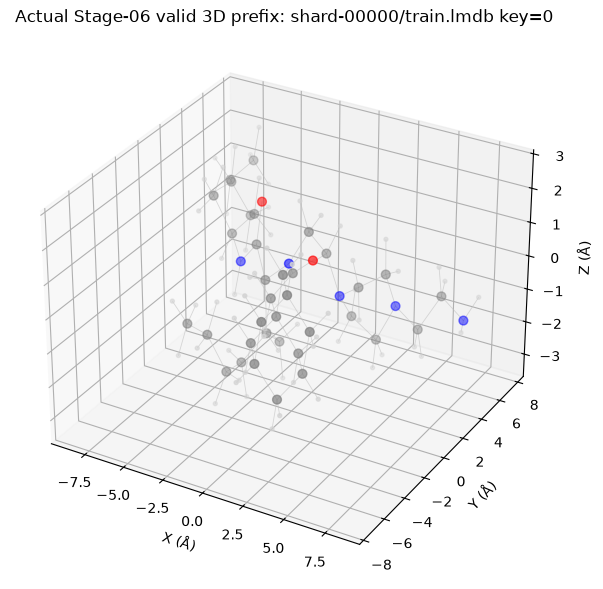

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/06_real_LMDB_molecular_conformer.png
ACTUAL LMDB PROBE: {'status': 'PILOT', 'generated_utc': '2026-11-17T23:16:55.062565+00:00', 'requested_probes': 10, 'actual_probes': 10, 'distinct_shards': 2, 'errors': 0, 'error_counts': {}, 'note': 'Sampled LMDB payload probe; does not replace full Stage-06 view verification.', 'representative_real_structure': {'shard': 'shard-00000/train.lmdb', 'key': 0, 'n3d': 10}}
Payload probe: PILOT | errors: 0


In [8]:
def probe_real_lmdb():
    try:import lmdb
    except ImportError as e: raise RuntimeError('Please install lmdb in the HPC notebook kernel') from e
    if not UGI_REPORT or not UGI_REPORT.get('audited_shards'):
        return {'status':'NOT_RUN','reason':'A successful metadata pilot is required first'}
    con=db_connect()
    choices=[]
    for (raw,) in con.execute('SELECT samples_json FROM done'):
        choices.extend(json.loads(raw))
    con.close()
    rng=random.Random(SEED)
    if len(choices)>MAX_PROBE_RECORDS:
        # Keep deliberate low-success examples and stratify remaining by source split.
        risk=[v for v in choices if v['selection']=='low_n3d']
        normal=[v for v in choices if v['selection']!='low_n3d']
        risks=rng.sample(risk,min(len(risk),MAX_PROBE_RECORDS//3))
        remaining=MAX_PROBE_RECORDS-len(risks)
        normal=rng.sample(normal,min(len(normal),remaining))
        choices=risks+normal
    if {'train','valid'}.issubset(set(SPLIT_BY_REL.values())) and {v['split'] for v in choices}!={'train','valid'}:
        raise RuntimeError('LMDB probe misses train or validation; increase MAX_PROBE_RECORDS or inspect split sampling')
    by_shard=defaultdict(list)
    for item in choices:by_shard[item['shard']].append(item)
    issues=[];record_rows=[]; representative=None
    for rel,subset in by_shard.items():
        try:
            env=lmdb.open(str(UGI/rel),subdir=False,readonly=True,lock=False,readahead=False,max_readers=4)
        except Exception as exc:
            for x in subset:issues.append({'shard':rel,'key':x['key'],'issue':'LMDB_open_failed','detail':repr(exc)})
            continue
        try:
            with env.begin(write=False) as txn:
                for spec in subset:
                    errs=[];key=spec['key'];item=None;zrange=None
                    try:
                        raw=txn.get(str(key).encode('ascii'))
                        if raw is None:raise KeyError('Missing numeric LMDB key')
                        item=pickle.loads(raw)
                        if not isinstance(item,dict):raise TypeError('LMDB record is not dict')
                        smi=item.get('smi');atoms=item.get('atoms');coords=item.get('coordinates')
                        can,mol=canonical_and_mol(smi);can_ref,_=canonical_and_mol(spec['smi'])
                        if can is None or can!=can_ref:errs.append('SMILES_identity_mismatch')
                        if not isinstance(atoms,(list,tuple)):errs.append('atoms_missing_or_wrong_type')
                        if not isinstance(coords,(list,tuple)) or len(coords)!=10:errs.append('coordinate_slots_not_10')
                        if mol is not None and isinstance(atoms,(list,tuple)):
                            reference_atoms=[a.GetSymbol() for a in Chem.AddHs(mol).GetAtoms()]
                            if list(atoms)!=reference_atoms:errs.append('atoms_differ_from_RDKit_AddHs')
                        n3d=int(spec['n3d']);conformer=None;zrange=None
                        if isinstance(coords,(list,tuple)):
                            for ix,c in enumerate(coords):
                                try:
                                    arr=np.asarray(c,dtype=float)
                                    if not isinstance(atoms,(list,tuple)) or arr.shape!=(len(atoms),3):errs.append(f'coordinate_shape_bad_slot_{ix}')
                                    if not np.all(np.isfinite(arr)):errs.append(f'nonfinite_slot_{ix}')
                                    if arr.size and np.max(np.abs(arr))>1e4:errs.append(f'extreme_coordinate_slot_{ix}')
                                    if ix==0:
                                        conformer=arr
                                        if arr.shape[1:]==(3,):zrange=float(np.ptp(arr[:,2]))
                                except Exception as e:errs.append(f'coordinates_parse_failed_slot_{ix}')
                        if not (1<=n3d<=10):errs.append('invalid_n3d_selected')
                        if not errs and representative is None and conformer is not None and zrange is not None and zrange>.01:
                            representative=(spec,atoms,conformer,mol)
                    except Exception as exc:
                        errs.append('unreadable_payload:'+repr(exc)[:160])
                    record_rows.append({'shard':rel,'split':spec['split'],'key':key,'n3d':spec['n3d'],
                                        'selection':spec['selection'],'errors':';'.join(errs),
                                        'z_range_first_success':zrange if item is not None else None})
                    for e in errs:issues.append({'shard':rel,'key':key,'issue':e,'smi':str(spec.get('smi'))[:180]})
        finally:env.close()
    pd.DataFrame(record_rows).to_csv(AUDIT/('05_real_lmdb_probe_rows.csv' if UGI_REPORT['scope']=='FULL' else '05_PILOT_lmdb_probe_rows.csv'),index=False)
    pd.DataFrame(issues,columns=['shard','key','issue','smi']).to_csv(AUDIT/('05_real_lmdb_probe_errors.csv' if UGI_REPORT['scope']=='FULL' else '05_PILOT_lmdb_probe_errors.csv'),index=False)
    report={'status':('COMPLETE' if UGI_REPORT['scope']=='FULL' else 'PILOT') if len(record_rows)==len(choices) else 'PARTIAL','generated_utc':utc_now(),'requested_probes':len(choices),
            'actual_probes':len(record_rows),'distinct_shards':len(by_shard),'errors':len(issues),
            'error_counts':dict(Counter(i['issue'] for i in issues)),
            'note':'Sampled LMDB payload probe; does not replace full Stage-06 view verification.'}
    write_json('05_real_lmdb_probe_summary.json' if UGI_REPORT['scope']=='FULL' else '05_PILOT_lmdb_probe_summary.json',report)
    if representative:
        spec,atoms,coords,mol=representative
        fig=plt.figure(figsize=(7,6));ax=fig.add_subplot(111,projection='3d')
        atom_colors={'C':'gray','H':'lightgray','N':'blue','O':'red','S':'orange','P':'purple'}
        colors=[atom_colors.get(a,'green') for a in atoms]
        ax.scatter(coords[:,0],coords[:,1],coords[:,2],c=colors,s=[40 if a!='H' else 8 for a in atoms],alpha=.9)
        if mol is not None:
            molH=Chem.AddHs(mol)
            if molH.GetNumAtoms()==len(coords):
                for b in molH.GetBonds():
                    i,j=b.GetBeginAtomIdx(),b.GetEndAtomIdx()
                    ax.plot([coords[i,0],coords[j,0]],[coords[i,1],coords[j,1]],
                            [coords[i,2],coords[j,2]],color='silver',linewidth=.6,alpha=.6)
        ax.set_title(f'Actual Stage-06 valid 3D prefix: {spec["shard"]} key={spec["key"]}')
        ax.set_xlabel('X (Å)');ax.set_ylabel('Y (Å)');ax.set_zlabel('Z (Å)')
        figsave('06_real_LMDB_molecular_conformer.png')
        report['representative_real_structure']={'shard':spec['shard'],'key':spec['key'],'n3d':spec['n3d']}
        write_json('05_real_lmdb_probe_summary.json' if UGI_REPORT['scope']=='FULL' else '05_PILOT_lmdb_probe_summary.json',report)
    print('ACTUAL LMDB PROBE:',report)
    return report

if RUN_LMDB_PROBE and UGI_REPORT and UGI_REPORT.get('audited_shards',0)>0:
    LMDB_REPORT=probe_real_lmdb()
else:
    LMDB_REPORT=read_json(AUDIT/'05_real_lmdb_probe_summary.json' if UGI_REPORT and UGI_REPORT.get('scope')=='FULL' else AUDIT/'05_PILOT_lmdb_probe_summary.json')
    if not LMDB_REPORT:LMDB_REPORT={'status':'NOT_RUN','reason':'RUN_LMDB_PROBE disabled or full audit incomplete'}
print('Payload probe:',LMDB_REPORT.get('status'),'| errors:',LMDB_REPORT.get('errors','UNKNOWN'))

## Full scan: interactive batches or automatic Slurm mode

In interactive mode, this cell does nothing unless you manually change `RUN_NEXT_BATCH` to `True`, and then each execution processes one batch of at most `BATCH_SHARDS` shards. **Do not click Run All expecting a full scan.**

When launched by the **new Slurm runner** with `HEART_AUDIT_AUTORUN=1`, this same cell checks both pilot results and automatically scans **all remaining shards**, with resumable SQLite commits. Once complete, the LMDB payload probe is repeated with `MAX_PROBE_RECORDS=3500` before making the final decision. Pilot failures stop the automated job; this protects the original dataset and avoids presenting an incomplete audit as a PASS.


UNATTENDED FULL AUDIT MODE: entered from explicit Slurm submission
Resumable SQLite: 2 complete; 3047 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 7, 'total_shards': 3049, 'completed_this_run': 5, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 3.1, 'last_shard': 'shard-00005/train.lmdb', 'updated_utc': '2026-11-17T23:16:59.672438+00:00'}
PARALLEL AUDIT: {'completed_shards': 12, 'total_shards': 3049, 'completed_this_run': 10, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 3.3, 'last_shard': 'shard-00010/train.lmdb', 'updated_utc': '2026-11-17T23:16:59.790539+00:00'}
PARALLEL AUDIT: {'completed_shards': 17, 'total_shards': 3049, 'completed_this_run': 15, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 3.4, 'last_shard': 'shard-00015/train.lmdb', 'updated_utc': '2026-11-17T23:16:59.967362+00:00'}
PARALLEL AUDIT: {'completed_shards': 22, 'total_shards': 3049, 'completed_this_run': 20, 'pending_this_run': 

PARALLEL AUDIT: {'completed_shards': 162, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 9.7, 'last_shard': 'shard-00160/train.lmdb', 'updated_utc': '2026-11-17T23:17:29.476218+00:00'}
AUTO FULL AUDIT PROGRESS: 162/3049 shards; 809,426 records; scope=INCOMPLETE
Resumable SQLite: 162 complete; 2887 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 167, 'total_shards': 3049, 'completed_this_run': 5, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 4.0, 'last_shard': 'shard-00165/train.lmdb', 'updated_utc': '2026-11-17T23:17:34.651286+00:00'}
PARALLEL AUDIT: {'completed_shards': 172, 'total_shards': 3049, 'completed_this_run': 10, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 5.0, 'last_shard': 'shard-00170/train.lmdb', 'updated_utc': '2026-11-17T23:17:35.567690+00:00'}
PARALLEL AUDIT: {'completed_shards': 177, 'total_shards': 3049, 'completed_this_run': 15, 'pe

PARALLEL AUDIT: {'completed_shards': 317, 'total_shards': 3049, 'completed_this_run': 35, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 11.3, 'last_shard': 'shard-00315/train.lmdb', 'updated_utc': '2026-11-17T23:18:18.525905+00:00'}
PARALLEL AUDIT: {'completed_shards': 322, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 12.5, 'last_shard': 'shard-00320/train.lmdb', 'updated_utc': '2026-11-17T23:18:19.755157+00:00'}
AUTO FULL AUDIT PROGRESS: 322/3049 shards; 1,605,952 records; scope=INCOMPLETE
Resumable SQLite: 322 complete; 2727 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 327, 'total_shards': 3049, 'completed_this_run': 5, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 4.4, 'last_shard': 'shard-00325/train.lmdb', 'updated_utc': '2026-11-17T23:18:24.897992+00:00'}
PARALLEL AUDIT: {'completed_shards': 332, 'total_shards': 3049, 'completed_this_run': 10,

PARALLEL AUDIT: {'completed_shards': 472, 'total_shards': 3049, 'completed_this_run': 30, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 11.9, 'last_shard': 'shard-00471/train.lmdb', 'updated_utc': '2026-11-17T23:19:18.311508+00:00'}
PARALLEL AUDIT: {'completed_shards': 477, 'total_shards': 3049, 'completed_this_run': 35, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 13.4, 'last_shard': 'shard-00476/train.lmdb', 'updated_utc': '2026-11-17T23:19:19.772952+00:00'}
PARALLEL AUDIT: {'completed_shards': 482, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 14.8, 'last_shard': 'shard-00481/train.lmdb', 'updated_utc': '2026-11-17T23:19:21.248912+00:00'}
AUTO FULL AUDIT PROGRESS: 482/3049 shards; 2,401,896 records; scope=INCOMPLETE
Resumable SQLite: 482 complete; 2567 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 487, 'total_shards': 3049, 'completed_this_run': 5

PARALLEL AUDIT: {'completed_shards': 627, 'total_shards': 3049, 'completed_this_run': 25, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 11.4, 'last_shard': 'shard-00626/train.lmdb', 'updated_utc': '2026-11-17T23:20:25.245717+00:00'}
PARALLEL AUDIT: {'completed_shards': 632, 'total_shards': 3049, 'completed_this_run': 30, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 13.0, 'last_shard': 'shard-00631/train.lmdb', 'updated_utc': '2026-11-17T23:20:26.878349+00:00'}
PARALLEL AUDIT: {'completed_shards': 637, 'total_shards': 3049, 'completed_this_run': 35, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 14.6, 'last_shard': 'shard-00636/train.lmdb', 'updated_utc': '2026-11-17T23:20:28.478507+00:00'}
PARALLEL AUDIT: {'completed_shards': 642, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 16.2, 'last_shard': 'shard-00641/train.lmdb', 'updated_utc': '2026-11-17T23:20:30.042421+00:00'}
AUTO FULL AUDIT PROG

PARALLEL AUDIT: {'completed_shards': 782, 'total_shards': 3049, 'completed_this_run': 20, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 10.0, 'last_shard': 'shard-00781/train.lmdb', 'updated_utc': '2026-11-17T23:21:36.816765+00:00'}
PARALLEL AUDIT: {'completed_shards': 787, 'total_shards': 3049, 'completed_this_run': 25, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 11.6, 'last_shard': 'shard-00786/train.lmdb', 'updated_utc': '2026-11-17T23:21:38.469018+00:00'}
PARALLEL AUDIT: {'completed_shards': 792, 'total_shards': 3049, 'completed_this_run': 30, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 13.3, 'last_shard': 'shard-00791/train.lmdb', 'updated_utc': '2026-11-17T23:21:40.123647+00:00'}
PARALLEL AUDIT: {'completed_shards': 797, 'total_shards': 3049, 'completed_this_run': 35, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 15.0, 'last_shard': 'shard-00796/train.lmdb', 'updated_utc': '2026-11-17T23:21:41.843741+00:00'}
PARALLEL AUDIT: {'co

... (10 outputs left out)

Resumable SQLite: 2482 complete; 567 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 2487, 'total_shards': 3049, 'completed_this_run': 5, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 5.2, 'last_shard': 'shard-02486/train.lmdb', 'updated_utc': '2026-11-17T23:36:51.412697+00:00'}
PARALLEL AUDIT: {'completed_shards': 2492, 'total_shards': 3049, 'completed_this_run': 10, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 7.2, 'last_shard': 'shard-02491/train.lmdb', 'updated_utc': '2026-11-17T23:36:53.493541+00:00'}
PARALLEL AUDIT: {'completed_shards': 2497, 'total_shards': 3049, 'completed_this_run': 15, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 9.2, 'last_shard': 'shard-02496/train.lmdb', 'updated_utc': '2026-11-17T23:36:55.442075+00:00'}
PARALLEL AUDIT: {'completed_shards': 2502, 'total_shards': 3049, 'completed_this_run': 20, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 11.1, 'last_shard'

PARALLEL AUDIT: {'completed_shards': 2642, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 19.2, 'last_shard': 'shard-02641/train.lmdb', 'updated_utc': '2026-11-17T23:38:18.136113+00:00'}
AUTO FULL AUDIT PROGRESS: 2642/3049 shards; 13,154,057 records; scope=INCOMPLETE
Resumable SQLite: 2642 complete; 407 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 2647, 'total_shards': 3049, 'completed_this_run': 5, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 5.7, 'last_shard': 'shard-02646/train.lmdb', 'updated_utc': '2026-11-17T23:38:29.089207+00:00'}
PARALLEL AUDIT: {'completed_shards': 2652, 'total_shards': 3049, 'completed_this_run': 10, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 7.7, 'last_shard': 'shard-02651/train.lmdb', 'updated_utc': '2026-11-17T23:38:31.169346+00:00'}
PARALLEL AUDIT: {'completed_shards': 2657, 'total_shards': 3049, 'completed_this_run'

PARALLEL AUDIT: {'completed_shards': 2797, 'total_shards': 3049, 'completed_this_run': 35, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 17.1, 'last_shard': 'shard-02796/train.lmdb', 'updated_utc': '2026-11-17T23:39:54.657241+00:00'}
PARALLEL AUDIT: {'completed_shards': 2802, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 19.1, 'last_shard': 'shard-02801/train.lmdb', 'updated_utc': '2026-11-17T23:39:56.610913+00:00'}
AUTO FULL AUDIT PROGRESS: 2802/3049 shards; 13,953,834 records; scope=INCOMPLETE
Resumable SQLite: 2802 complete; 247 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 2807, 'total_shards': 3049, 'completed_this_run': 5, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 5.5, 'last_shard': 'shard-02806/train.lmdb', 'updated_utc': '2026-11-17T23:40:07.423807+00:00'}
PARALLEL AUDIT: {'completed_shards': 2812, 'total_shards': 3049, 'completed_this_run

PARALLEL AUDIT: {'completed_shards': 2952, 'total_shards': 3049, 'completed_this_run': 30, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 15.6, 'last_shard': 'shard-02951/train.lmdb', 'updated_utc': '2026-11-17T23:41:33.340662+00:00'}
PARALLEL AUDIT: {'completed_shards': 2957, 'total_shards': 3049, 'completed_this_run': 35, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 17.5, 'last_shard': 'shard-02956/train.lmdb', 'updated_utc': '2026-11-17T23:41:35.331001+00:00'}
PARALLEL AUDIT: {'completed_shards': 2962, 'total_shards': 3049, 'completed_this_run': 40, 'pending_this_run': 40, 'workers': 24, 'elapsed_seconds': 19.5, 'last_shard': 'shard-02961/train.lmdb', 'updated_utc': '2026-11-17T23:41:37.308305+00:00'}
AUTO FULL AUDIT PROGRESS: 2962/3049 shards; 14,751,519 records; scope=INCOMPLETE
Resumable SQLite: 2962 complete; 87 pending; workers=24
Selected pending shards for THIS call: 40
PARALLEL AUDIT: {'completed_shards': 2967, 'total_shards': 3049, 'completed_this_ru

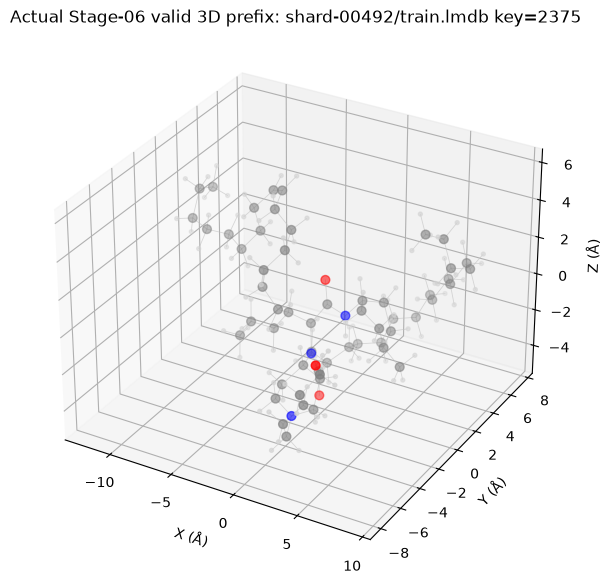

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/06_real_LMDB_molecular_conformer.png
ACTUAL LMDB PROBE: {'status': 'COMPLETE', 'generated_utc': '2026-11-17T23:43:30.915131+00:00', 'requested_probes': 3500, 'actual_probes': 3500, 'distinct_shards': 2162, 'errors': 0, 'error_counts': {}, 'note': 'Sampled LMDB payload probe; does not replace full Stage-06 view verification.', 'representative_real_structure': {'shard': 'shard-00492/train.lmdb', 'key': 2375, 'n3d': 2}}
FINAL LMDB PROBE: {'status': 'COMPLETE', 'generated_utc': '2026-11-17T23:43:30.915131+00:00', 'requested_probes': 3500, 'actual_probes': 3500, 'distinct_shards': 2162, 'errors': 0, 'error_counts': {}, 'note': 'Sampled LMDB payload probe; does not replace full Stage-06 view verification.', 'representative_real_structure': {'shard': 'shard-00492/train.lmdb', 'key': 2375, 'n3d': 2}}


In [9]:
# INTERACTIVE DEFAULT: no automatic full scan when pressing Jupyter Run All.
RUN_NEXT_BATCH = False
BATCH_SHARDS = int(os.getenv('HEART_AUDIT_BATCH_SHARDS', '40'))
AUTO_FULL_FROM_SLURM = os.getenv('HEART_AUDIT_AUTORUN', '0') == '1'

if AUTO_FULL_FROM_SLURM:
    print('UNATTENDED FULL AUDIT MODE: entered from explicit Slurm submission', flush=True)
    if not all(preflight_report['packages'].values()):
        raise RuntimeError('Preflight failed: required Python packages are missing. See 00_preflight.json')
    if not UGI_REPORT or not UGI_REPORT.get('audited_shards'):
        raise RuntimeError('Metadata pilot did not complete; full audit not started')
    if LMDB_REPORT.get('status') not in ('PILOT', 'COMPLETE') or LMDB_REPORT.get('errors', 0):
        raise RuntimeError('Real LMDB pilot failed; inspect 05_PILOT_lmdb_probe_errors.csv before rerunning')
    con = db_connect()
    pilot_stats = [json.loads(row[0]) for row in con.execute('SELECT stats_json FROM done')]
    con.close()
    pilot_blockers = ['noncontiguous_keys', 'bad_3d_count', 'sidecar_disagreement',
                      'invalid_smiles', 'fragmented_smiles']
    pilot_problems = [(x['shard'], key, x.get(key, 0))
                      for x in pilot_stats for key in pilot_blockers if x.get(key, 0)]
    if pilot_problems:
        write_json('03_pilot_blockers.json', pilot_problems)
        raise RuntimeError('Metadata pilot identified blocking anomalies; inspect 03_pilot_blockers.json')

    while UGI_REPORT['scope'] != 'FULL':
        before = UGI_REPORT['audited_shards']
        full_audit(max_shards=BATCH_SHARDS)
        UGI_REPORT = summarize_full_audit()
        print(f'AUTO FULL AUDIT PROGRESS: {UGI_REPORT["audited_shards"]}/{UGI_REPORT["expected_shards"]} shards; '
              f'{UGI_REPORT["audited_records"]:,} records; scope={UGI_REPORT["scope"]}', flush=True)
        if UGI_REPORT['audited_shards'] <= before:
            raise RuntimeError('Audit made no progress; inspect 03_live_progress.json and logs')

    MAX_PROBE_RECORDS = 3500
    print('FULL metadata scan finished; checking sampled real LMDB records...',flush=True)
    LMDB_REPORT = probe_real_lmdb()
    print('FINAL LMDB PROBE:',LMDB_REPORT,flush=True)

elif RUN_NEXT_BATCH:
    if not UGI_REPORT or not UGI_REPORT.get('audited_shards'):
        print('BLOCKED: First run the metadata pilot and LMDB pilot.')
    elif LMDB_REPORT.get('status') not in ('PILOT','COMPLETE') or LMDB_REPORT.get('errors',0)>0:
        print('BLOCKED: LMDB pilot incomplete or contains errors; resolve before full scan.',LMDB_REPORT)
    else:
        full_audit(max_shards=BATCH_SHARDS)
        UGI_REPORT=summarize_full_audit()
        print('Completed:',UGI_REPORT['audited_shards'],'/',UGI_REPORT['expected_shards'],
              'shards; scope=',UGI_REPORT['scope'])
        print('Completed records:',UGI_REPORT['audited_records'])
        print('Progress:',AUDIT/'03_live_progress.json')
        if UGI_REPORT['scope']=='FULL':
            print('FULL SCAN FINISHED. Rerun the LMDB probe with MAX_PROBE_RECORDS=3500, then run final figures/reports.')
else:
    print('Interactive pilot-only mode. No full scan and NO Slurm job submitted.')


## Interactive progress visualization — truthfully labeled as partial or full

This figure is updated from the SQLite records completed so far; it is **not** an estimate for unaudited shards. Running this cell after each batch provides a real progress chart, plus the number of issues already found. No molecular quality claim is made about remaining shards.


,Audit scope,Audited shards,Expected shards,Audited records,Known invalid SMILES,Known index mismatches
0,FULL,3049,3049,15182715,0,0


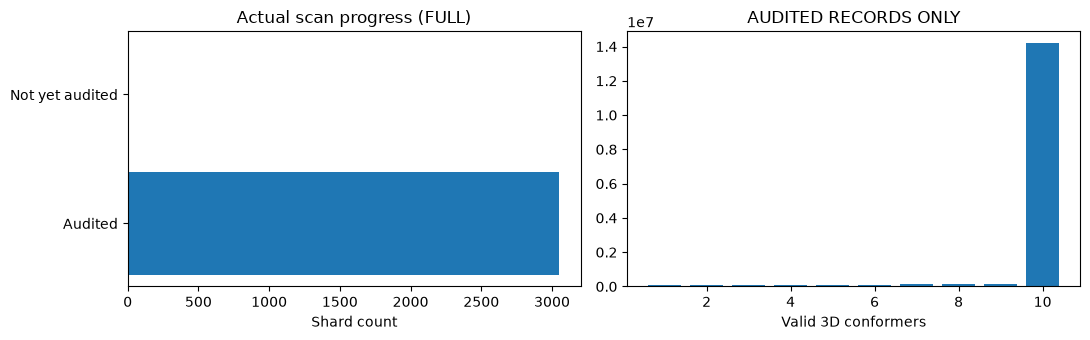

SQLite cache and all original LMDB files remain unchanged.


In [10]:
if UGI_REPORT:
    st=UGI_REPORT
    display(pd.DataFrame([{'Audit scope':st['scope'],'Audited shards':st['audited_shards'],
                           'Expected shards':st['expected_shards'],
                           'Audited records':st['audited_records'],
                           'Known invalid SMILES':st['issues_full_counts'].get('invalid_smiles',0),
                           'Known index mismatches':st['issues_full_counts'].get('sidecar_disagreement',0)}]))
    fig,axs=plt.subplots(1,2,figsize=(11,3.5))
    axs[0].barh(['Audited','Not yet audited'],[st['audited_shards'],st['expected_shards']-st['audited_shards']])
    axs[0].set_xlabel('Shard count');axs[0].set_title('Actual scan progress ('+st['scope']+')')
    hist={int(k):v for k,v in st['n3d_histogram'].items()}
    axs[1].bar(range(1,11),[hist.get(i,0) for i in range(1,11)])
    axs[1].set_xlabel('Valid 3D conformers');axs[1].set_title('AUDITED RECORDS ONLY')
    fig.tight_layout();fig.savefig(PLOTS/'PILOT_or_PARTIAL_progress.png',dpi=170,bbox_inches='tight')
    plt.show();plt.close(fig)
    print('SQLite cache and all original LMDB files remain unchanged.')
else:print('No metadata pilot completed yet.')


## Final evidence / forensics / loader review — run only after full scan

The next cells preserve the original final-stage analyses: exact duplicate forensic examples, full-data visualizations, production loader static inspection, and evidence-based readiness summary. **Do not treat the partial audit as complete**. The report remains `INCOMPLETE` until all shards and sampled payload checks have been completed.


## 3B | Forensic examples of actual molecules when duplication or leakage is detected

If the full scan finds canonical duplicates or train/validation leakage, select a small number of matching molecular digests from SQLite and revisit `records.csv.gz` to identify the actual SMILES, source shard, and record key. This is **traceable molecular evidence**, not merely a duplicate count, and it does not alter training data. If no duplicates or leakage are found, explicitly report that there is no forensic target to display.


In [11]:
FORENSIC_ROWS=[]
if UGI_REPORT and UGI_REPORT['scope']=='FULL' and RUN_FORENSIC_EXAMPLES:
    con=db_connect()
    targets={}
    cross=con.execute('SELECT hash,n_train,n_valid,n_total FROM molecules WHERE n_train>0 AND n_valid>0 ORDER BY hash LIMIT 8').fetchall()
    duplicates=con.execute('SELECT hash,n_train,n_valid,n_total FROM molecules WHERE n_total>1 ORDER BY hash LIMIT 8').fetchall()
    for label,rows in [('train_valid_leakage',cross),('duplicate_molecule',duplicates)]:
        for h,nt,nv,tot in rows:
            t=targets.setdefault(h,{'kinds':set(),'n_train':nt,'n_valid':nv,'n_total':tot,'hits':[]})
            t['kinds'].add(label)
    con.close()
    if targets:
        for rel,entry in MANIFEST_BY_REL.items():
            if all((len(t['hits'])>=2 and
                    ('train_valid_leakage' not in t['kinds'] or
                     {'train','valid'}.issubset({x['split'] for x in t['hits']}))) for t in targets.values()):
                break
            path=UGI/Path(rel).parent/'records.csv.gz'
            with gzip.open(path,'rt',encoding='utf-8',newline='') as f:
                for row in csv.DictReader(f):
                    can,_=canonical_and_mol(row.get('smi'))
                    if not can:continue
                    h=fp(can)
                    if h in targets:
                        t=targets[h]; split=SPLIT_BY_REL[rel]
                        need=('train_valid_leakage' in t['kinds'] and
                              split not in {x['split'] for x in t['hits']})
                        if len(t['hits'])<2 or need:
                            t['hits'].append({'split':split,'shard':rel,'key':row.get('key'),'canonical_smiles':can})
        for h,t in targets.items():
            for x in t['hits']:
                FORENSIC_ROWS.append({'categories':','.join(sorted(t['kinds'])),'digest_hex':h.hex(),
                    'canonical_smiles':x['canonical_smiles'],'n_train':t['n_train'],'n_valid':t['n_valid'],
                    'n_total':t['n_total'],'split':x['split'],'shard':x['shard'],'key':x['key']})
        print('Selected molecular identities:',len(targets),'| source occurrences recovered:',len(FORENSIC_ROWS))
    else:print('No canonical duplicate or cross-split leakage identities in the FULL index.')
else:
    print('Forensic example recovery unavailable or disabled; do not interpret as 0 duplicates.')
pd.DataFrame(FORENSIC_ROWS,columns=['categories','digest_hex','canonical_smiles','n_train','n_valid','n_total','split','shard','key']).to_csv(AUDIT/'03b_molecular_forensic_examples.csv',index=False)
if FORENSIC_ROWS:display(pd.DataFrame(FORENSIC_ROWS).head(24))

No canonical duplicate or cross-split leakage identities in the FULL index.


## 4 | Visual evidence from the completed full metadata audit

**Only plot measurements obtained from the full dataset.** Figures cover train versus validation records, number of usable 3D conformers, molecular size, Ugi-like motif coverage, duplicate excess, and cross-split molecular leakage. Values come from the actual metadata and SQLite audit, **not from extrapolating a sample**.


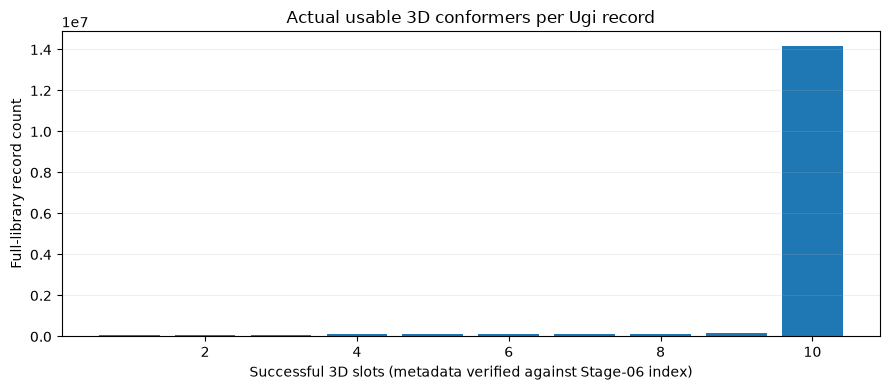

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/02_metadata_3d_success.png


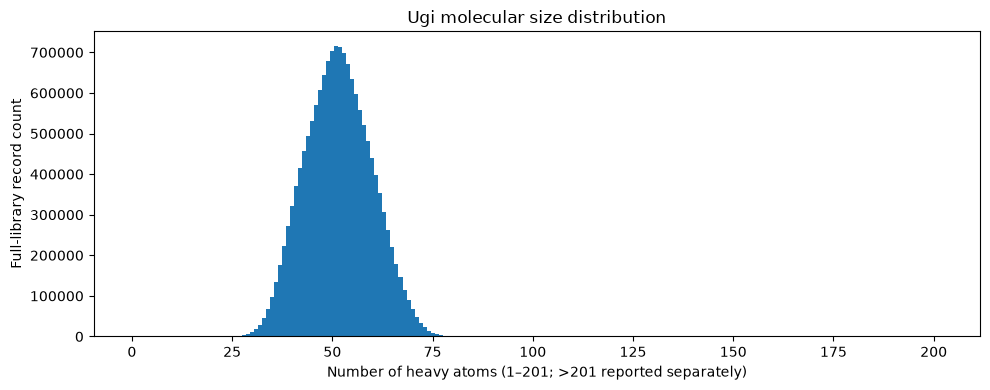

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/03_heavy_atom_distribution.png


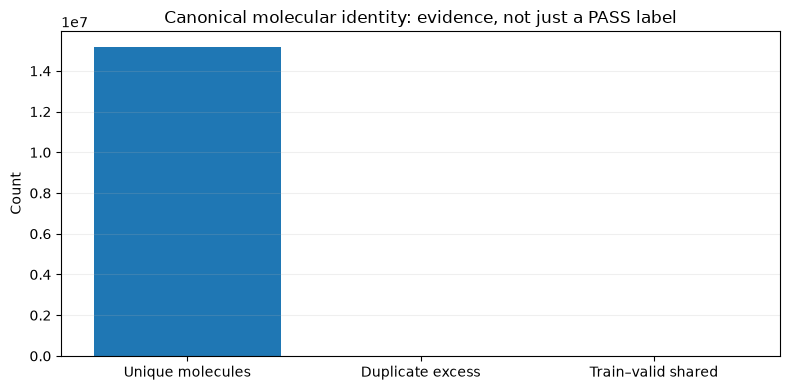

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/04_identity_overlap_counts.png


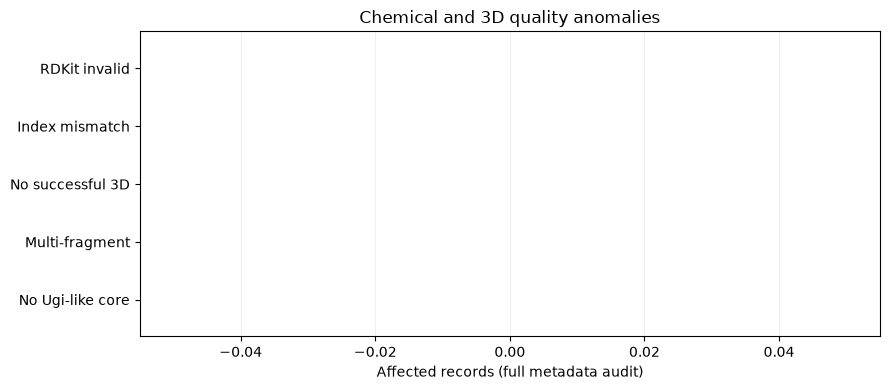

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/05_full_audit_anomalies.png


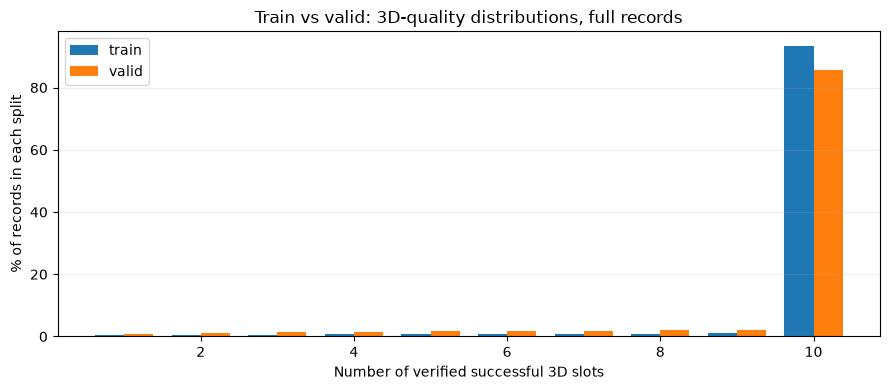

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/05b_train_valid_3d_distribution.png


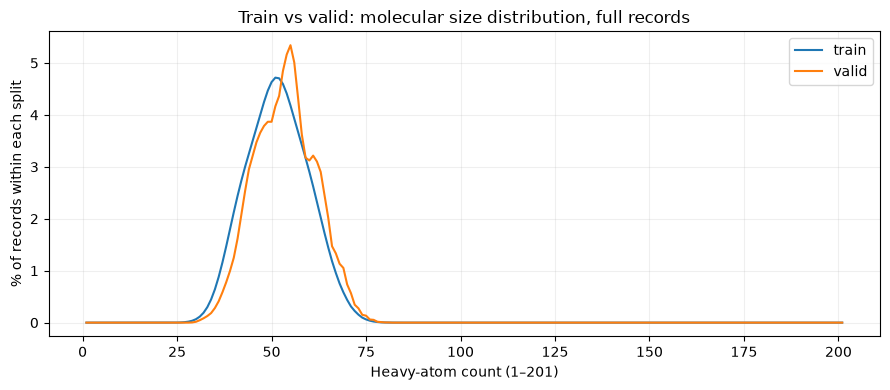

Figure: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/figures/05c_train_valid_heavy_atoms.png


In [12]:
if UGI_REPORT and UGI_REPORT['scope']=='FULL':
    n3d={int(k):int(v) for k,v in UGI_REPORT['n3d_histogram'].items()}
    heavy={int(k):int(v) for k,v in UGI_REPORT['heavy_atom_histogram_cap513'].items()}
    plt.figure(figsize=(9,4))
    plt.bar(range(1,11),[n3d.get(k,0) for k in range(1,11)])
    plt.xlabel('Successful 3D slots (metadata verified against Stage-06 index)')
    plt.ylabel('Full-library record count');plt.grid(axis='y',alpha=.2)
    plt.title('Actual usable 3D conformers per Ugi record');figsave('02_metadata_3d_success.png')
    plt.figure(figsize=(10,4))
    x=np.arange(1,202)
    plt.bar(x,[heavy.get(int(k),0) for k in x],width=1)
    plt.xlabel('Number of heavy atoms (1–201; >201 reported separately)')
    plt.ylabel('Full-library record count');plt.title('Ugi molecular size distribution');figsave('03_heavy_atom_distribution.png')
    vals=[UGI_REPORT['unique_canonical_molecules_hash_based'],UGI_REPORT['duplicate_excess_records'],
          UGI_REPORT['canonical_train_valid_intersection']]
    plt.figure(figsize=(8,4));plt.bar(['Unique molecules','Duplicate excess','Train–valid shared'],vals)
    plt.ylabel('Count');plt.title('Canonical molecular identity: evidence, not just a PASS label')
    plt.grid(axis='y',alpha=.2);figsave('04_identity_overlap_counts.png')
    fractions=UGI_REPORT['issues_full_counts']
    labels=['RDKit invalid','Index mismatch','No successful 3D','Multi-fragment','No Ugi-like core']
    nums=[fractions.get('invalid_smiles',0),fractions.get('sidecar_disagreement',0),
          fractions.get('bad_3d_count',0),fractions.get('fragmented_smiles',0),
          fractions.get('without_ugi_like_motif',0)]
    plt.figure(figsize=(9,4));plt.barh(labels[::-1],nums[::-1])
    plt.xlabel('Affected records (full metadata audit)');plt.title('Chemical and 3D quality anomalies')
    plt.grid(axis='x',alpha=.2);figsave('05_full_audit_anomalies.png')

    # Actual train/valid 3D distribution, aggregated from full per-shard metadata.
    con=db_connect(); hist_by_split={'train':Counter(),'valid':Counter()}; heavy_by_split={'train':Counter(),'valid':Counter()}
    for (raw,) in con.execute('SELECT stats_json FROM done'):
        sh=json.loads(raw);sp=sh['split']
        if sp not in hist_by_split:continue
        hist_by_split[sp].update({int(k):int(v) for k,v in sh.get('n3d_hist',{}).items()})
        heavy_by_split[sp].update({int(k):int(v) for k,v in sh.get('heavy_hist',{}).items()})
    con.close()
    x=np.arange(1,11); width=.38
    plt.figure(figsize=(9,4))
    for sp,offset in [('train',-width/2),('valid',width/2)]:
        h=hist_by_split[sp];den=max(1,sum(h.values()))
        plt.bar(x+offset,[100*h.get(int(k),0)/den for k in x],width,label=sp)
    plt.xlabel('Number of verified successful 3D slots');plt.ylabel('% of records in each split')
    plt.title('Train vs valid: 3D-quality distributions, full records');plt.legend()
    plt.grid(axis='y',alpha=.2);figsave('05b_train_valid_3d_distribution.png')
    x=np.arange(1,202)
    plt.figure(figsize=(9,4))
    for sp in ['train','valid']:
        h=heavy_by_split[sp];den=max(1,sum(h.values()))
        plt.plot(x,[100*h.get(int(k),0)/den for k in x],label=sp)
    plt.xlabel('Heavy-atom count (1–201)');plt.ylabel('% of records within each split')
    plt.title('Train vs valid: molecular size distribution, full records');plt.legend()
    plt.grid(alpha=.2);figsave('05c_train_valid_heavy_atoms.png')

else: print('Figures withheld until FULL metadata audit is complete; partial != clean.')

## 6 | Production loader and training readiness — separate from molecular data validity

Even if the data and 3D index checks pass, we must confirm that **the production loader actually samples only the 3D slots permitted by `n_3d_success`**. If the original LMDB still includes fallback slots, using a loader without Stage-06 protections could reintroduce invalid coordinates.

This section inventories relevant source-code references and the General checkpoint, with an optional `bin/heart continual --dry-run` check. **Static code searches provide audit clues, not proof of correct runtime behavior.** `RUN_PRODUCTION_DRY_RUN=False` by default, so this notebook does not submit a training job.


In [13]:
LOADER={'general_checkpoint_exists':GENERAL_CKPT.is_file(),'general_checkpoint_path':str(GENERAL_CKPT),
        'repo_exists':REPO.is_dir(),'code_evidence':[],'dry_run':'NOT_RUN'}
if REPO.is_dir():
    tokens=['n_3d_success','final_dataset_view','library_3d_ready','3d_success','valid_3d','index_file']
    for p in REPO.rglob('*.py'):
        if len(LOADER['code_evidence'])>=60:break
        try:
            if p.stat().st_size>800000 or any(part in {'site-packages','.venv','third_party','.git'} for part in p.parts):continue
            for lineno,line in enumerate(p.read_text(encoding='utf-8',errors='ignore').splitlines(),1):
                if any(x in line for x in tokens):
                    LOADER['code_evidence'].append({'path':str(p),'line_number':lineno,'text':line.strip()[:190]})
                    if len(LOADER['code_evidence'])>=60:break
        except (OSError,PermissionError):pass
if RUN_PRODUCTION_DRY_RUN:
    launcher=REPO/'bin/heart'
    if not launcher.is_file():LOADER['dry_run']='FAILED: missing bin/heart'
    else:
        try:
            r=subprocess.run([str(launcher),'continual','--dry-run'],cwd=str(REPO),capture_output=True,text=True,timeout=900)
            (AUDIT/'06_production_dry_run.log').write_text(r.stdout+'\nSTDERR\n'+r.stderr)
            LOADER['dry_run']='EXIT_0' if r.returncode==0 else 'EXIT_'+str(r.returncode)
        except Exception as e:LOADER['dry_run']='ERROR: '+repr(e)
write_json('06_production_loader_review.json',LOADER)
print('General checkpoint exists:',LOADER['general_checkpoint_exists'])
print('Static sidecar/valid-3D code hits:',len(LOADER['code_evidence']))
print('dry-run:',LOADER['dry_run'])
if LOADER['code_evidence']:display(pd.DataFrame(LOADER['code_evidence'][:20]))
print('IMPORTANT: A code hit or exit 0 alone cannot prove that the training iterator uses only successful 3D slots. Inspect actual run configuration / sampled batch.')

General checkpoint exists: True
Static sidecar/valid-3D code hits: 38
dry-run: NOT_RUN


,path,line_number,text
0,/mnt/home/ypan/heart_liver/model_train/heart-m...,26,"produced here carries `n_3d_success`, `n_2d_fi..."
1,/mnt/home/ypan/heart_liver/model_train/heart-m...,154,"stats[""n_3d_success""] = len(out)"
2,/mnt/home/ypan/heart_liver/model_train/heart-m...,196,"""retry_heavy_then_addhs"": 0, ""n_3d_success"": 0,"
3,/mnt/home/ypan/heart_liver/model_train/heart-m...,74,"""n_coordinate_slots"", ""n_3d_success"", ""n_2d_fi..."
4,/mnt/home/ypan/heart_liver/model_train/heart-m...,392,"""n_3d_success_hist"": {}, ""n_distinct_3d_hist"":..."
5,/mnt/home/ypan/heart_liver/model_train/heart-m...,437,"if s[""n_3d_success""] == 0 and not opts.allow_2..."
6,/mnt/home/ypan/heart_liver/model_train/heart-m...,443,"s[""n_heavy_atoms""], s[""n_coordinate_slots""], s..."
7,/mnt/home/ypan/heart_liver/model_train/heart-m...,447,"stats[""n_3d_slots_total""] += s[""n_3d_success""]"
8,/mnt/home/ypan/heart_liver/model_train/heart-m...,454,"for hk, hv in ((""n_3d_success_hist"", s[""n_3d_s..."
9,/mnt/home/ypan/heart_liver/model_train/heart-m...,94,"for hk, col in ((""n_3d_success_hist"", ""n_3d_su..."


IMPORTANT: A code hit or exit 0 alone cannot prove that the training iterator uses only successful 3D slots. Inspect actual run configuration / sampled batch.


## 7 | Evidence-based readiness decision: counts, charts, anomalies, and next actions

Report only conclusions supported by checks that actually ran:

- **`HOLD`:** confirmed defects in source integrity, chemical validity, sidecars, sampled LMDB payloads, or train/validation molecular leakage.
- **`INCOMPLETE`:** missing datasets, unreadable evidence, or unfinished scans; do **not** assume the dataset passed.
- **`REVIEW`:** key data checks are satisfactory, but duplicate sampling policy, historical Stage-05 failures, or production-loader behavior still require review.
- **`GO_DATA`:** the complete molecular / 3D metadata audit and sampled payload check have identified no blocking data issue. This means **data-ready for a carefully controlled dry-run**, not that the model already learns lipid delivery.

Production execution readiness is reported separately as `PENDING_RUNTIME_VERIFICATION`, so a dataset-quality result cannot be mistaken for authorization to launch a training run.


In [14]:
blockers=[];unknown=[];reviews=[];context_notes=[];production_reviews=[];positives=[]
for issue in INV['issues']:
    if issue.startswith('MISSING ') or 'unavailable' in issue:unknown.append(issue)
    else:blockers.append(issue)
for issue in sidecar_issues[:20]:
    if issue.startswith('NOT_RUN') or issue.startswith('MISSING '):unknown.append(issue)
    else:blockers.append(issue)
if not UGI_REPORT or UGI_REPORT['scope']!='FULL':
    unknown.append('Full 15M metadata canonical scan missing or incomplete; no exact duplicate / leakage conclusion')
else:
    u=UGI_REPORT
    if not u.get('identity_accounting_matches',False):
        blockers.append('Canonical identity count mismatch: unique+duplicate excess != valid SMILES records')
    if u['audited_records']==u['expected_records'] and u['audited_shards']==u['expected_shards']:
        positives.append(f'All {u["audited_records"]:,} metadata records in {u["audited_shards"]:,} shards audited')
    for name in ['noncontiguous_keys','bad_3d_count','sidecar_disagreement','invalid_smiles','fragmented_smiles']:
        count=u['issues_full_counts'].get(name,0)
        if count:blockers.append(f'{name}: {count:,} affected records')
        else:positives.append(f'Zero {name} across full metadata scan')
    if u['canonical_train_valid_intersection']>0:
        blockers.append(f'Canonical train/validation leakage: {u["canonical_train_valid_intersection"]:,} molecules')
    else:positives.append('Zero canonical molecular overlap between train and validation')
    if u['duplicate_excess_records']>0:
        reviews.append(f'Train/library duplicate excess = {u["duplicate_excess_records"]:,}; document sampling/dedup policy before production')
    if u['issues_full_counts'].get('without_ugi_like_motif',0)>0:
        reviews.append(f'{u["issues_full_counts"]["without_ugi_like_motif"]:,} records do not contain broad Ugi-like motif; review chemistry, this motif is only diagnostic')
    if u['issues_full_counts'].get('heavy_over_256',0)>0:
        reviews.append(f'{u["issues_full_counts"]["heavy_over_256"]:,} molecules exceed 256 heavy atoms; verify actual production model max atoms (256 is not automatically HEART limit)')
if not SIDE_REPORT or SIDE_REPORT['scope']!='FULL_VIEW_SCAN':unknown.append('Full Stage-06 view census not completed')
elif SIDE_REPORT.get('n_total_issues',0)==0 and SIDE_REPORT['counted_records']==SIDE_REPORT['declared_records']:
    positives.append('Stage-06 successful-3D sidecar index exists, has valid range, and covers all declared records')
if LMDB_REPORT.get('status')!='COMPLETE':unknown.append('Real LMDB payload probe not run')
elif LMDB_REPORT.get('errors',0)>0:blockers.append(f'{LMDB_REPORT["errors"]} actual LMDB probe errors')
else:positives.append(f'{LMDB_REPORT["actual_probes"]:,} actual LMDB sampled payloads passed structural/coordinate checks')
if qc and qc.get('passed') is False:
    reviews.append('Historical Stage-05 QC marked FAIL; confirm its precise cause and documented Stage-06 resolution (do not overwrite history)')
if not LOADER['general_checkpoint_exists']:
    production_reviews.append('Expected General checkpoint not located at configured path')
context_notes.append('Whole-shard train/valid split is not reagent-holdout or scaffold-holdout; interpret ID validation accordingly')
if LOADER['dry_run']!='EXIT_0':production_reviews.append('Production loader/dry-run has not been dynamically verified on this dataset')
else:positives.append('Documented bin/heart continual --dry-run exited successfully; inspect its logged input configuration')

if blockers:gate='HOLD'
elif unknown:gate='INCOMPLETE'
elif reviews:gate='REVIEW'
else:gate='GO_DATA'
PRODUCTION_GATE='PENDING_RUNTIME_VERIFICATION' if LOADER['dry_run']!='EXIT_0' else 'INSPECT_DRY_RUN_EVIDENCE'
REPORT={'generated_utc':utc_now(),'data_gate':gate,'production_gate':PRODUCTION_GATE,
        'blockers':blockers,'unknown':unknown,'reviews':reviews,'production_reviews':production_reviews,'context_notes':context_notes,'positives':positives,
        'inventory':INV,'full_ugi':UGI_REPORT,'sidecar':SIDE_REPORT,'payload_probe':LMDB_REPORT,
        'production_check':LOADER,'figures':sorted(p.name for p in PLOTS.glob('*.png')),
        'disclaimer':'Data readiness cannot prove continual-pretraining performance or LNP delivery efficacy. No training submitted.'}
write_json('07_priority1_evidence_decision.json',REPORT)
lines=['# HEART Ugi-4CR | Priority 1 evidence decision',
       f'**Data gate: {gate}** | **Production gate: {PRODUCTION_GATE}**',
       f'Generated UTC: {REPORT["generated_utc"]}','',
       '## Actual measurement summary',
       f'- Expected / audited: {UGI_REPORT.get("audited_records") if UGI_REPORT else "UNKNOWN"} / {UGI_REPORT.get("expected_records") if UGI_REPORT else "UNKNOWN"} records',
       f'- Unique canonical molecules: {UGI_REPORT.get("unique_canonical_molecules_hash_based") if UGI_REPORT else "UNKNOWN"}',
       f'- Duplicate excess: {UGI_REPORT.get("duplicate_excess_records") if UGI_REPORT else "UNKNOWN"}',
       f'- Train/valid shared molecules: {UGI_REPORT.get("canonical_train_valid_intersection") if UGI_REPORT else "UNKNOWN"}',
       f'- 3D sidecar indexed records: {SIDE_REPORT.get("counted_records")}',
       f'- Real LMDB payload probes: {LMDB_REPORT.get("actual_probes","NOT_RUN")} | errors: {LMDB_REPORT.get("errors","UNKNOWN")}',
       '','## Positive evidence']
lines.extend('- '+x for x in positives or ['None established yet'])
lines.extend(['','## Confirmed blockers']);lines.extend('- '+x for x in blockers or ['None'])
lines.extend(['','## Still unknown']);lines.extend('- '+x for x in unknown or ['None'])
lines.extend(['','## Review before production']);lines.extend('- '+x for x in reviews or ['None'])
lines.extend(['','## Production-only review']);lines.extend('- '+x for x in production_reviews or ['None'])
lines.extend(['','## Context / limitations']);lines.extend('- '+x for x in context_notes or ['None'])
lines.extend(['','## Saved figures']);lines.extend('- '+x for x in REPORT['figures'] or ['No figures yet'])
lines.extend(['','## Interpretation',
  'Stage-06 safe 3D-prefix policy must be enforced by the actual training loader; a valid sidecar is necessary but not sufficient.',
  'Stage-05 historical status is not rewritten. No automatic dataset modification or training submission.'])
(AUDIT/'07_priority1_evidence_decision.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
display(Markdown('\n'.join(lines)))
print('Final evidence:',AUDIT/'07_priority1_evidence_decision.json')

# HEART Ugi-4CR | Priority 1 evidence decision
**Data gate: REVIEW** | **Production gate: PENDING_RUNTIME_VERIFICATION**
Generated UTC: 2026-11-17T23:44:33.647511+00:00

## Actual measurement summary
- Expected / audited: 15182715 / 15182715 records
- Unique canonical molecules: 15182715
- Duplicate excess: 0
- Train/valid shared molecules: 0
- 3D sidecar indexed records: 15182715
- Real LMDB payload probes: 3500 | errors: 0

## Positive evidence
- All 15,182,715 metadata records in 3,049 shards audited
- Zero noncontiguous_keys across full metadata scan
- Zero bad_3d_count across full metadata scan
- Zero sidecar_disagreement across full metadata scan
- Zero invalid_smiles across full metadata scan
- Zero fragmented_smiles across full metadata scan
- Zero canonical molecular overlap between train and validation
- Stage-06 successful-3D sidecar index exists, has valid range, and covers all declared records
- 3,500 actual LMDB sampled payloads passed structural/coordinate checks

## Confirmed blockers
- None

## Still unknown
- None

## Review before production
- Historical Stage-05 QC marked FAIL; confirm its precise cause and documented Stage-06 resolution (do not overwrite history)

## Production-only review
- Production loader/dry-run has not been dynamically verified on this dataset

## Context / limitations
- Whole-shard train/valid split is not reagent-holdout or scaffold-holdout; interpret ID validation accordingly

## Saved figures
- 01_full_3d_success_histogram.png
- 02_metadata_3d_success.png
- 03_heavy_atom_distribution.png
- 04_identity_overlap_counts.png
- 05_full_audit_anomalies.png
- 05b_train_valid_3d_distribution.png
- 05c_train_valid_heavy_atoms.png
- 06_real_LMDB_molecular_conformer.png
- PILOT_metadata_3d_success.png
- PILOT_or_PARTIAL_progress.png

## Interpretation
Stage-06 safe 3D-prefix policy must be enforced by the actual training loader; a valid sidecar is necessary but not sufficient.
Stage-05 historical status is not rewritten. No automatic dataset modification or training submission.

Final evidence: /mnt/home/ypan/heart_liver/model_train/ugi_priority1_interactive_evidence/07_priority1_evidence_decision.json


## 8 | How to present these findings to the PI

**Claims supported by completed tests (replace placeholders with actual HPC results):**

- “We scanned **X records across Y shards**. The observed Stage-06 3D-success distribution is shown in the figures, with **Z metadata-versus-sidecar mismatches**.”
- “The library contains **A unique canonical molecules**, **B excess duplicate records**, and **C molecules shared between training and validation**.”
- “We inspected **N real LMDB records**, observed **E payload errors**, and retained molecular coordinate visualizations and forensic anomaly examples.”
- “The existence of the General checkpoint and production-loader runtime readiness were assessed separately.”

**Claims that the audit does not support:**

- The existence of `library_3d_ready.json` by itself proves that all coordinates were individually validated physically or visually.
- The library uses exactly the same sampling strategy or model weights as LUMI; that requires a separate pretraining-configuration review.
- A whole-shard validation split measures generalization to novel Ugi building blocks.
- A dataset-quality PASS proves that HEART predicts mTP, or that adding LNPDB necessarily improves performance.

**Next study task (Priority 2):** characterize LNPDB molecular overlap, test 3D-compatible ingestion, and design a controlled General / Ugi / LNPDB mixed-sampling strategy.

**Where to read results:** `/home/ypan/heart_liver/model_train/ugi_priority1_evidence/07_priority1_evidence_decision.md`, including the `figures/` directory. The SQLite cache is stored separately and does not need to be opened in the Jupyter file browser.

**Unattended execution:** `sbatch HEART_Ugi_Priority1_model_train_run.sbatch` while you work on your review. Check `squeue -u "$USER"`, Slurm logs, and the output folder. If interrupted, the per-shard SQLite index may be resumed on a second identical run.


In [ ]:

from pathlib import Path
import os

# ============================================================
# HEART / Ugi-4CR / LNPDB — HPC Path Configuration
# ============================================================

# 1. Project storage
PROJECT_ROOT = Path("/project/yli4/ypan")
LIPID_LIBRARY_ROOT = PROJECT_ROOT / "lipid_library"
INPUT_DIR = LIPID_LIBRARY_ROOT / "input"

# 2. Input datasets
LNPDB_PATH = INPUT_DIR / "LNPDB.csv"
LUMI_LIBRARY_PATH = (
    INPUT_DIR / "LUMI_virtual_library_training_lipidLike.xlsx"
)

# 3. Existing Ugi-4CR molecular library
UGI_LMDB_DIR = LIPID_LIBRARY_ROOT / "lmdb"

# 4. Existing HEART model directory
HOME = Path.home()
MODEL_TRAIN_DIR = HOME / "heart_liver" / "model_train"

# 5. Previously completed Priority 1 audit
PRIORITY1_RESULTS = (
    MODEL_TRAIN_DIR / "ugi_priority1_interactive_evidence"
)

PRIORITY1_DECISION = (
    PRIORITY1_RESULTS / "07_priority1_evidence_decision.json"
)

PRIORITY1_MOLECULAR_AUDIT = (
    PRIORITY1_RESULTS / "03_full_molecular_audit.json"
)

# 6. Priority 2 output directory
PRIORITY2_RESULTS = (
    MODEL_TRAIN_DIR / "ugi_lnpdb_priority2_evidence"
)

PRIORITY2_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# Validate paths before running any analysis
# ============================================================

required_files = {
    "LNPDB CSV": LNPDB_PATH,
    "LUMI virtual library": LUMI_LIBRARY_PATH,
    "Priority 1 molecular audit": PRIORITY1_MOLECULAR_AUDIT,
    "Priority 1 decision": PRIORITY1_DECISION,
}

required_directories = {
    "Ugi LMDB directory": UGI_LMDB_DIR,
    "HEART model directory": MODEL_TRAIN_DIR,
}

print("=" * 65)
print("HEART / LNPDB / Ugi-4CR — Path Verification")
print("=" * 65)

missing = []

for name, path in required_files.items():
    exists = path.is_file()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    print(f"  {path}")
    if not exists:
        missing.append(str(path))

for name, path in required_directories.items():
    exists = path.is_dir()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")
    print(f"  {path}")
    if not exists:
        missing.append(str(path))

print("\nOutput directory:")
print(PRIORITY2_RESULTS)

if missing:
    print("\nWARNING: Some required paths were not found.")
    for path in missing:
        print(" -", path)
else:
    print("\nAll required paths verified successfully.")

# ============================================================
# Preview LNPDB dataset
# ============================================================

if LNPDB_PATH.is_file():
    import pandas as pd

    lnpdb_df = pd.read_csv(LNPDB_PATH, low_memory=False)

    print("\nLNPDB dataset loaded successfully.")
    print("Total records:", len(lnpdb_df))
    print("Columns:", list(lnpdb_df.columns))

    display(lnpdb_df.head())